# Hướng 1 — Temporal Recommendation Baseline

**Người thực hiện: Cường Quốc**  
Dataset: All Beauty đã làm sạch, dùng bốn cột `user_id`, `parent_asin`, `rating`, `timestamp`.

Notebook tiếp nối `02_item_based_cf.ipynb`. Kết quả gồm cấu hình được chọn trên validation, bảng đánh giá test của Most Popular và ItemCF, mô hình đã lưu và bản tổng hợp để viết báo cáo.

## Quy ước đánh giá được chốt trước

- Tương tác tích cực: rating từ 4 sao trở lên theo `split_config.json`. Đây là quy ước từ dữ liệu review.
- Học trên train, thử số sản phẩm lân cận **N = 10, 20, 50, 100** trên validation. Số sản phẩm trả về là **K = 10 hoặc 20**; N và K là hai tham số khác nhau.
- Chọn N có **NDCG@10 cao nhất trên toàn bộ người dùng validation đủ điều kiện đánh giá**. Nếu bằng nhau, chọn Recall@10 cao hơn, rồi N nhỏ hơn. Lưu quyết định trước khi đọc test.
- Huấn luyện lại bằng **train + validation**, giữ nguyên N đã chọn; đánh giá test và báo cáo cả hai mô hình.
- Mỗi người trong tập đánh giá phải có ít nhất một sản phẩm tích cực chưa đánh giá trong lịch sử. Tính trung bình theo người dùng, kể cả người không có hit. Báo cáo thêm nhóm đã có ít nhất một tương tác tích cực trong lịch sử.
- Hai mô hình dùng cùng tập ứng viên: toàn bộ sản phẩm xuất hiện trong lịch sử huấn luyện. Loại sản phẩm người dùng từng đánh giá ở bất kỳ mức sao nào. Sản phẩm mới trong tập đánh giá vẫn ở ground truth và được tính là miss nếu mô hình không gợi ý được.

Giữ nguyên tập test cho đánh giá cuối. Nếu xây dựng phương pháp mới sau khi xem kết quả này, ghi rõ đó là một thí nghiệm mới; không chọn lại tham số theo kết quả test hiện tại.



In [1]:
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import scipy
import sklearn

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / 'data' / 'processed'
REPORT_DIR = PROJECT_DIR / 'reports' / 'final_cf'
MODEL_DIR = PROJECT_DIR / 'models' / 'item_cf_final'
SELECTION_PATH = REPORT_DIR / 'selected_config.json'

CORE_COLUMNS = ['user_id', 'parent_asin', 'rating', 'timestamp']
NEIGHBOR_GRID = (10, 20, 50, 100)
BLOCK_SIZE = 1024
K_VALUES = (10, 20)
PRIMARY_K = 10
BOOTSTRAP_RESAMPLES = 1000
SEED = 42
CF_LABEL = 'ItemCF + Popular fallback'
POPULAR_LABEL = 'Most Popular'


def write_json(path, value):
    def convert(obj):
        if isinstance(obj, np.generic):
            return obj.item()
        raise TypeError(f'Không thể ghi kiểu {type(obj).__name__} ra JSON.')
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2,
                                    allow_nan=False, default=convert), encoding='utf-8')


print('Thư mục dự án:', PROJECT_DIR)
print('Python:', platform.python_version())
print('pandas:', pd.__version__, '| scipy:', scipy.__version__, '| sklearn:', sklearn.__version__)
print('N thử trên validation:', NEIGHBOR_GRID, '| K trả về:', K_VALUES)


Thư mục dự án: d:\Tài Liệu\RecommenderSystem
Python: 3.12.10
pandas: 3.0.6 | scipy: 1.18.1 | sklearn: 1.9.1
N thử trên validation: (10, 20, 50, 100) | K trả về: (10, 20)


### Cấu hình phần temporal và bảo toàn baseline

Giữ mặc định cho lần chạy đầu. Sao lưu chỉ xảy ra khi đã có tệp baseline; thư mục sao lưu nằm dưới `models/` vốn đã được loại khỏi Git. Bảng ứng viên được ghi theo luồng vào CSV nén để tránh đưa hàng triệu dòng vào RAM.


In [2]:
# Phần mở rộng chỉ ghi đầu ra mới vào temporal_cf và models/.
from datetime import datetime, timezone
import shutil

HALF_LIFE_GRID = (90, 180, 365)
CANDIDATE_K = 100
MAKE_HANDOFF_ZIP = True
PRESERVE_PREVIOUS_BASELINE = True
TEMPORAL_LABEL = 'Time-decay ItemCF + Popular fallback'
TEMPORAL_REPORT_DIR = PROJECT_DIR / 'reports' / 'temporal_cf'
TEMPORAL_MODEL_DIR = PROJECT_DIR / 'models' / 'item_cf_temporal'
TEMPORAL_SELECTION_PATH = TEMPORAL_REPORT_DIR / 'selected_config.json'
HANDOFF_DIR = PROJECT_DIR / 'models' / 'member2_handoff'
for directory in [TEMPORAL_REPORT_DIR, TEMPORAL_MODEL_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
if (not HALF_LIFE_GRID or len(set(HALF_LIFE_GRID)) != len(HALF_LIFE_GRID)
        or any(not isinstance(h, int) or h <= 0 for h in HALF_LIFE_GRID)):
    raise ValueError('HALF_LIFE_GRID cần các số ngày nguyên dương, khác nhau.')
if CANDIDATE_K < max(K_VALUES):
    raise ValueError('CANDIDATE_K cần >= K lớn nhất trong đánh giá.')

# Run All vẫn chạy lại baseline theo mã cũ. Sao lưu tệp cũ trước khi ghi kết quả.
if PRESERVE_PREVIOUS_BASELINE:
    existing = [p for p in [REPORT_DIR, MODEL_DIR] if p.is_dir() and any(p.iterdir())]
    if existing:
        run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
        archive_root = PROJECT_DIR / 'models' / 'baseline_archive' / run_id
        for source in existing:
            shutil.copytree(source, archive_root / source.name)
        print('Đã sao lưu baseline cũ:', archive_root)
print('Temporal h (ngày):', HALF_LIFE_GRID)
print('K ứng viên mỗi người dùng/biến thể:', CANDIDATE_K)
print('Kết quả temporal:', TEMPORAL_REPORT_DIR)


Đã sao lưu baseline cũ: d:\Tài Liệu\RecommenderSystem\models\baseline_archive\20261024T073401_522966Z
Temporal h (ngày): (90, 180, 365)
K ứng viên mỗi người dùng/biến thể: 100
Kết quả temporal: d:\Tài Liệu\RecommenderSystem\reports\temporal_cf


## 1. Đọc train và validation

Sử dụng đúng các mốc thời gian đã lưu ở notebook 01. Bước này chỉ đọc train và validation; test được đọc sau khi đã lưu cấu hình được chọn.


In [3]:
required = [DATA_DIR / 'train.parquet', DATA_DIR / 'validation.parquet',
            DATA_DIR / 'split_config.json']
missing = [p.name for p in required if not p.is_file()]
if missing:
    raise FileNotFoundError('Thiếu ' + ', '.join(missing)
                            + '. Đặt notebook trong thư mục dự án và chạy bước chia tập ở notebook 01.')

split_config = json.loads((DATA_DIR / 'split_config.json').read_text(encoding='utf-8'))
if split_config.get('split_method') != 'global_chronological':
    raise ValueError('Notebook này sử dụng cách chia global_chronological của notebook 01.')
if split_config.get('item_column') != 'parent_asin':
    raise ValueError('Cột sản phẩm cần là parent_asin để khớp notebook 01 và 02.')
POSITIVE_THRESHOLD = float(split_config['positive_rating_threshold'])
if POSITIVE_THRESHOLD != 4.0:
    raise ValueError('Thí nghiệm này chốt rating >= 4; cần khớp cấu hình notebook 01 và 02.')


def validate_frame(frame, name):
    if frame.empty or frame[CORE_COLUMNS].isna().any().any():
        raise ValueError(f'{name}: tập rỗng hoặc thiếu giá trị ở cột lõi.')
    if not frame['rating'].isin([1, 2, 3, 4, 5]).all():
        raise ValueError(f'{name}: rating cần thuộc 1, 2, 3, 4, 5.')
    if not pd.api.types.is_integer_dtype(frame['timestamp']):
        raise ValueError(f'{name}: timestamp cần là số nguyên mili giây.')
    if not frame['timestamp'].between(10**11, 10**14).all():
        raise ValueError(f'{name}: kiểm tra lại đơn vị timestamp mili giây.')
    if frame.duplicated(['user_id', 'parent_asin', 'timestamp']).any():
        raise ValueError(f'{name}: có sự kiện trùng user, item và timestamp.')


train = pd.read_parquet(DATA_DIR / 'train.parquet', columns=CORE_COLUMNS)
val = pd.read_parquet(DATA_DIR / 'validation.parquet', columns=CORE_COLUMNS)
for name, frame in [('train', train), ('validation', val)]:
    validate_frame(frame, name)
assert train['timestamp'].max() <= split_config['train_end_timestamp_ms']
assert val['timestamp'].min() > split_config['train_end_timestamp_ms']
assert val['timestamp'].max() <= split_config['validation_end_timestamp_ms']
assert train['timestamp'].max() < val['timestamp'].min()

REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
display(pd.DataFrame([
    {'Tập': name, 'Dòng': len(frame), 'Người dùng': frame.user_id.nunique(),
     'Sản phẩm': frame.parent_asin.nunique()}
    for name, frame in [('Train', train), ('Validation', val)]
]))


,Tập,Dòng,Người dùng,Sản phẩm
0,Train,485977,448900,78488
1,Validation,138850,129945,39637


## 2. Khai báo mô hình và hàm đánh giá

ItemCF sử dụng ma trận nhị phân của các cặp user–item tích cực khác nhau. Độ tương tự sản phẩm là cosine giữa các vector người dùng. Mỗi sản phẩm giữ tối đa N sản phẩm lân cận có cosine dương; điểm ứng viên là tổng độ tương tự với các sản phẩm người dùng đã đánh giá tích cực. Khi thiếu ứng viên CF, danh sách được bổ sung bằng Most Popular từ cùng lịch sử.

Tính cosine theo khối ma trận thưa để phù hợp máy RAM 16 GB với dữ liệu này. Không tạo ma trận đặc có kích thước số sản phẩm nhân số sản phẩm. Thứ tự khi bằng điểm được cố định theo `parent_asin`.

`CF_slot_fraction` là tỷ lệ vị trí do CF cung cấp. `popular_only_list_fraction` là tỷ lệ người dùng nhận danh sách hoàn toàn từ Most Popular. Các chỉ số được lưu ở thang 0–1; CatalogCoverage là tỷ lệ sản phẩm xuất hiện trong ít nhất một danh sách trên danh mục của giai đoạn đó.

Ô mã dưới đây chỉ khai báo lớp và hàm; các ô tiếp theo mới chạy huấn luyện và đánh giá.


In [4]:
from pathlib import Path
from collections import defaultdict
from time import perf_counter
import hashlib
import json
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.preprocessing import normalize


class ItemCFModel:
    """Binary item cosine CF with train-only popularity fallback."""

    def __init__(self, n_neighbors=50, positive_threshold=4.0, block_size=1024):
        if n_neighbors < 1 or block_size < 1:
            raise ValueError('Số lân cận và kích thước khối phải dương.')
        self.n_neighbors = int(n_neighbors)
        self.positive_threshold = float(positive_threshold)
        self.block_size = int(block_size)

    def fit(self, history):
        started = perf_counter()
        columns = ['user_id', 'parent_asin', 'rating', 'timestamp']
        if history.empty or history[columns].isna().any().any():
            raise ValueError('Lịch sử huấn luyện rỗng hoặc thiếu cột lõi.')
        if not history['rating'].isin([1, 2, 3, 4, 5]).all():
            raise ValueError('Lịch sử có rating không hợp lệ.')
        positive = history[history['rating'] >= self.positive_threshold].drop_duplicates(
            ['user_id', 'parent_asin'])
        if positive.empty:
            raise ValueError('Lịch sử không có tương tác tích cực để học CF.')
        self.item_ids = pd.Index(sorted(history['parent_asin'].unique()), name='parent_asin')
        self.user_ids = pd.Index(positive['user_id'].unique(), name='user_id')
        self.user_to_index = {u: i for i, u in enumerate(self.user_ids)}
        self.warm_users = set(self.user_ids)
        self.catalog = set(self.item_ids)
        self.seen = defaultdict(set)
        for user, item in history[['user_id', 'parent_asin']].itertuples(index=False, name=None):
            self.seen[user].add(item)
        self.popularity = (positive.groupby('parent_asin').size()
            .reindex(self.item_ids, fill_value=0).rename('positive_user_count').reset_index()
            .sort_values(['positive_user_count', 'parent_asin'], ascending=[False, True])
            .reset_index(drop=True))
        self.popular_ids = self.popularity['parent_asin'].tolist()
        rows = self.user_ids.get_indexer(positive['user_id'])
        cols = self.item_ids.get_indexer(positive['parent_asin'])
        self.R = sparse.csr_matrix(
            (np.ones(len(positive), dtype=np.float32), (rows, cols)),
            shape=(len(self.user_ids), len(self.item_ids)), dtype=np.float32)
        assert self.R.nnz == len(positive)
        assert np.all(self.R.data == 1)
        vectors = normalize(self.R.T.tocsr(), norm='l2', axis=1, copy=True)
        right = vectors.T.tocsc()
        index_chunks, value_chunks, indptr = [], [], [0]
        for start in range(0, len(self.item_ids), self.block_size):
            stop = min(start + self.block_size, len(self.item_ids))
            block = (vectors[start:stop] @ right).tocsr()
            block.sum_duplicates()
            for local in range(stop - start):
                a, b = block.indptr[local:local + 2]
                indices, values = block.indices[a:b], block.data[a:b]
                keep = (indices != start + local) & (values > 0)
                indices, values = indices[keep], values[keep]
                order = np.lexsort((indices, -values))[:self.n_neighbors]
                if len(order):
                    index_chunks.append(indices[order].astype(np.int32, copy=False))
                    value_chunks.append(values[order].astype(np.float32, copy=False))
                indptr.append(indptr[-1] + len(order))
        indices = np.concatenate(index_chunks) if index_chunks else np.array([], dtype=np.int32)
        values = np.concatenate(value_chunks) if value_chunks else np.array([], dtype=np.float32)
        self.S = sparse.csr_matrix(
            (values, indices, np.asarray(indptr, dtype=np.int64)),
            shape=(len(self.item_ids), len(self.item_ids)), dtype=np.float32)
        self.S.sort_indices()
        self.S.eliminate_zeros()
        assert np.all(self.S.diagonal() == 0)
        assert np.diff(self.S.indptr).max(initial=0) <= self.n_neighbors
        assert np.isfinite(self.S.data).all()
        assert np.all((self.S.data > 0) & (self.S.data <= 1.000001))
        self.training_rows = int(len(history))
        self.positive_pairs = int(len(positive))
        self.history_end_timestamp_ms = int(history['timestamp'].max())
        self.training_fingerprint = hashlib.sha256(
            pd.util.hash_pandas_object(history[columns], index=False).values.tobytes()
        ).hexdigest()
        self.fit_seconds = perf_counter() - started
        return self

    def recommend_popular(self, user_id, k=10, return_info=False):
        if k < 1:
            raise ValueError('k phải lớn hơn hoặc bằng 1.')
        seen, result = self.seen.get(user_id, set()), []
        for item in self.popular_ids:
            if item not in seen:
                result.append(item)
                if len(result) == k:
                    break
        return (result, 0) if return_info else result

    def recommend(self, user_id, k=10, return_info=False):
        if k < 1:
            raise ValueError('k phải lớn hơn hoặc bằng 1.')
        seen, result = self.seen.get(user_id, set()), []
        index = self.user_to_index.get(user_id)
        if index is not None:
            scores = (self.R[index:index + 1] @ self.S).tocsr()
            candidates, values = scores.indices, scores.data
            keep = np.array([value > 0 and self.item_ids[i] not in seen
                             for i, value in zip(candidates, values)], dtype=bool)
            candidates, values = candidates[keep], values[keep]
            order = np.lexsort((candidates, -values))[:k]
            result = [self.item_ids[i] for i in candidates[order]]
        cf_count = len(result)
        if len(result) < k:
            chosen = set(result)
            for item in self.popular_ids:
                if item not in seen and item not in chosen:
                    result.append(item)
                    chosen.add(item)
                    if len(result) == k:
                        break
        return (result, cf_count) if return_info else result

    def save(self, destination, extra_config=None):
        destination = Path(destination)
        destination.mkdir(parents=True, exist_ok=True)
        sparse.save_npz(destination / 'user_item_train.npz', self.R)
        sparse.save_npz(destination / 'item_neighbors.npz', self.S)
        pd.DataFrame({'item_index': np.arange(len(self.item_ids)),
                      'parent_asin': self.item_ids}).to_csv(destination / 'items.csv', index=False)
        pd.DataFrame({'user_index': np.arange(len(self.user_ids)),
                      'user_id': self.user_ids}).to_csv(
            destination / 'users.csv.gz', index=False, compression='gzip')
        self.popularity.to_csv(destination / 'popularity.csv', index=False)
        seen_rows = ((user, item) for user, items in self.seen.items() for item in sorted(items))
        pd.DataFrame(seen_rows, columns=['user_id', 'parent_asin']).to_csv(
            destination / 'seen_history.csv.gz', index=False, compression='gzip')
        config = {'n_neighbors': self.n_neighbors, 'positive_threshold': self.positive_threshold,
                  'block_size': self.block_size, 'training_rows': self.training_rows,
                  'positive_pairs': self.positive_pairs, 'history_end_timestamp_ms': self.history_end_timestamp_ms,
                  'training_fingerprint': self.training_fingerprint, 'fit_seconds': self.fit_seconds,
                  'extra': extra_config or {}}
        (destination / 'model_config.json').write_text(
            json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')

    @classmethod
    def load(cls, directory):
        directory = Path(directory)
        cfg = json.loads((directory / 'model_config.json').read_text(encoding='utf-8'))
        obj = cls(cfg['n_neighbors'], cfg['positive_threshold'], cfg['block_size'])
        obj.R = sparse.load_npz(directory / 'user_item_train.npz').tocsr()
        obj.S = sparse.load_npz(directory / 'item_neighbors.npz').tocsr()
        items = pd.read_csv(directory / 'items.csv', dtype={'parent_asin': 'string'},
                            keep_default_na=False).sort_values('item_index')
        users = pd.read_csv(directory / 'users.csv.gz', dtype={'user_id': 'string'},
                            keep_default_na=False).sort_values('user_index')
        obj.item_ids = pd.Index(items['parent_asin'], name='parent_asin')
        obj.user_ids = pd.Index(users['user_id'], name='user_id')
        obj.user_to_index = {u: i for i, u in enumerate(obj.user_ids)}
        obj.warm_users, obj.catalog = set(obj.user_ids), set(obj.item_ids)
        obj.popularity = pd.read_csv(directory / 'popularity.csv', dtype={'parent_asin': 'string'},
                                     keep_default_na=False)
        obj.popular_ids = obj.popularity['parent_asin'].tolist()
        obj.seen = defaultdict(set)
        seen = pd.read_csv(directory / 'seen_history.csv.gz',
                           dtype={'user_id': 'string', 'parent_asin': 'string'}, keep_default_na=False)
        for user, item in seen.itertuples(index=False, name=None):
            obj.seen[user].add(item)
        for key in ['training_rows','positive_pairs','history_end_timestamp_ms','training_fingerprint','fit_seconds']:
            setattr(obj, key, cfg[key])
        assert obj.R.shape == (len(obj.user_ids), len(obj.item_ids))
        assert obj.S.shape == (len(obj.item_ids), len(obj.item_ids))
        return obj


def make_truth(held_out, model):
    positive = held_out[held_out['rating'] >= model.positive_threshold][
        ['user_id', 'parent_asin']].drop_duplicates()
    truth, excluded = defaultdict(set), 0
    for user, item in positive.itertuples(index=False, name=None):
        if item in model.seen.get(user, set()):
            excluded += 1
        else:
            truth[user].add(item)
    if not truth:
        raise ValueError('Tập đánh giá không còn cặp liên quan sau khi loại sản phẩm đã đánh giá.')
    diagnostics = {'users':len(truth), 'users_with_positive_history':sum(u in model.warm_users for u in truth),
                   'novel_positive_pairs':sum(map(len,truth.values())),
                   'excluded_seen_pairs':excluded,
                   'positive_pairs_with_items_unseen_in_history':sum(
                       item not in model.catalog for items in truth.values() for item in items)}
    return truth, diagnostics


def evaluate_model(model, truth, label, use_cf=True, k_values=(10,20), progress=False):
    started = perf_counter()
    recommender = model.recommend if use_cf else model.recommend_popular
    discounts = 1 / np.log2(np.arange(2,max(k_values)+2))
    rows, coverage = [], defaultdict(set)
    for position,(user,relevant) in enumerate(truth.items(),start=1):
        recs,cf_count = recommender(user,k=max(k_values),return_info=True)
        assert len(recs)<=max(k_values) and len(recs)==len(set(recs))
        assert set(recs).isdisjoint(model.seen.get(user,set()))
        assert set(recs).issubset(model.catalog)
        warm = user in model.warm_users
        for k in k_values:
            chosen=recs[:k]
            hits=np.array([item in relevant for item in chosen],dtype=float)
            hit_count=hits.sum()
            ideal=discounts[:min(k,len(relevant))].sum()
            rows.append({'model':label,'user_id':user,'k':k,'has_positive_history':warm,
                         'precision':hit_count/k,'recall':hit_count/len(relevant),
                         'ndcg':float((hits*discounts[:len(hits)]).sum()/ideal),
                         'cf_count':min(cf_count,k)})
            coverage[(k,'Toàn bộ')].update(chosen)
            if warm: coverage[(k,'Có lịch sử tích cực')].update(chosen)
        if progress and position%25000==0:
            print(f'{label}: {position:,}/{len(truth):,} người dùng')
    per_user=pd.DataFrame(rows)
    summaries=[]
    for k in k_values:
        selected=per_user[per_user.k==k]
        for cohort,group in [('Toàn bộ',selected),('Có lịch sử tích cực',selected[selected.has_positive_history])]:
            summaries.append({'model':label,'k':k,'group':cohort,'users':len(group),
                              'Precision@K':group.precision.mean(),'Recall@K':group.recall.mean(),
                              'NDCG@K':group.ndcg.mean(),
                              'CatalogCoverage@K':len(coverage[(k,cohort)])/len(model.item_ids),
                              'CF_slot_fraction':(group.cf_count/k).mean(),
                              'popular_only_list_fraction':group.cf_count.eq(0).mean()})
    return pd.DataFrame(summaries),per_user,perf_counter()-started


def paired_bootstrap_delta(cf_rows,popular_rows,k=10,n_resamples=1000,seed=42):
    left=cf_rows[cf_rows.k==k][['user_id','has_positive_history','ndcg']]
    right=popular_rows[popular_rows.k==k][['user_id','ndcg']]
    paired=left.merge(right,on='user_id',how='inner',suffixes=('_cf','_popular'),validate='one_to_one')
    assert len(paired)==len(left)==len(right)
    result=[]
    for cohort,group in [('Toàn bộ',paired),('Có lịch sử tích cực',paired[paired.has_positive_history])]:
        delta=(group.ndcg_cf-group.ndcg_popular).to_numpy()
        if not len(delta):continue
        rng=np.random.default_rng(seed)
        means=np.empty(n_resamples,dtype=float)
        for b in range(n_resamples):
            indices=rng.integers(0,len(delta),size=len(delta))
            means[b]=delta[indices].mean()
        lo,hi=np.quantile(means,[.025,.975])
        result.append({'group':cohort,'users':len(delta),'k':k,
                       'mean_NDCG_delta_CF_minus_Popular':float(delta.mean()),
                       'CI95_low':float(lo),'CI95_high':float(hi),'bootstrap_resamples':n_resamples,
                       'CI_contains_zero':bool(lo<=0<=hi)})
    return pd.DataFrame(result)


### 2.1. Temporal ItemCF và hợp đồng điểm xếp hạng

Không học lại cosine có trọng số thời gian: chỉ thay trọng số đóng góp của lịch sử tích cực. Mỗi cặp user–item lấy timestamp review tích cực mới nhất trong đúng lịch sử đã học baseline.

`score_time(u,i) = Σ_j 2^(-(t_ref - t_uj) / 86400000 / h) × S[j,i]`.

`None` tương ứng h = ∞ để kiểm tra khớp baseline. `scored_recommendations` bổ sung điểm thô, nguồn CF/fallback và một điểm vô hướng giữ nguyên thứ tự; điểm đó không phải xác suất mua.


In [5]:
class TimeDecayItemCF:
    """Keep baseline cosine/fallback; decay each positive history contribution."""

    def __init__(self, base_model, half_life_days=None, reference_timestamp_ms=None):
        if half_life_days is not None and (
                not np.isfinite(half_life_days) or half_life_days <= 0):
            raise ValueError('Chu kỳ bán rã phải dương; dùng None cho đối chứng không decay.')
        self.base_model = base_model
        self.half_life_days = None if half_life_days is None else float(half_life_days)
        self.reference_timestamp_ms = int(
            base_model.history_end_timestamp_ms if reference_timestamp_ms is None
            else reference_timestamp_ms)
        if self.reference_timestamp_ms < base_model.history_end_timestamp_ms:
            raise ValueError('Mốc dự đoán không được trước cuối lịch sử huấn luyện.')

    def __getattr__(self, name):
        return getattr(self.base_model, name)

    def fit_weights(self, history):
        columns = ['user_id', 'parent_asin', 'rating', 'timestamp']
        if history.empty or history[columns].isna().any().any():
            raise ValueError('Lịch sử tính trọng số rỗng hoặc thiếu giá trị lõi.')
        fingerprint = hashlib.sha256(
            pd.util.hash_pandas_object(history[columns], index=False).values.tobytes()
        ).hexdigest()
        if fingerprint != self.base_model.training_fingerprint:
            raise ValueError('Trọng số phải dùng đúng lịch sử và thứ tự đã học baseline.')
        if int(history.timestamp.max()) > self.reference_timestamp_ms:
            raise ValueError('Lịch sử có sự kiện sau mốc dự đoán.')
        positive_times = (history[history.rating >= self.positive_threshold]
            .groupby(['user_id', 'parent_asin'], sort=False, as_index=False)
            .agg(timestamp=('timestamp', 'max')))
        rows = self.user_ids.get_indexer(positive_times.user_id)
        cols = self.item_ids.get_indexer(positive_times.parent_asin)
        if (rows < 0).any() or (cols < 0).any() or len(rows) != self.base_model.R.nnz:
            raise ValueError('Các cặp tích cực không khớp baseline.')
        age_days = (self.reference_timestamp_ms
                    - positive_times.timestamp.to_numpy(dtype=np.float64)) / 86_400_000.0
        if (age_days < 0).any():
            raise ValueError('Không được dùng review tương lai để tính tuổi tương tác.')
        if self.half_life_days is None:
            # Giữ float32 để đối chứng khớp đúng phép cộng của baseline.
            self.R_time = self.base_model.R.copy()
        else:
            weights = np.exp2(-age_days / self.half_life_days)
            if not np.isfinite(weights).all() or (weights <= 0).any():
                raise ValueError('Trọng số bị tràn/underflow; kiểm tra timestamp và chu kỳ.')
            self.R_time = sparse.csr_matrix(
                (weights, (rows, cols)), shape=self.base_model.R.shape, dtype=np.float64)
            self.R_time.sort_indices()
        if (self.R_time.astype(bool) != self.base_model.R.astype(bool)).nnz:
            raise ValueError('Temporal chỉ được đổi trọng số, không được đổi cặp lịch sử.')
        return self

    def recommend(self, user_id, k=10, return_info=False):
        if k < 1:
            raise ValueError('k phải lớn hơn hoặc bằng 1.')
        if not hasattr(self, 'R_time'):
            raise ValueError('Cần gọi fit_weights hoặc load trước khi dự đoán.')
        seen, result = self.seen.get(user_id, set()), []
        index = self.user_to_index.get(user_id)
        if index is not None:
            scores = (self.R_time[index:index + 1] @ self.S).tocsr()
            candidates, values = scores.indices, scores.data
            keep = np.array([value > 0 and self.item_ids[i] not in seen
                             for i, value in zip(candidates, values)], dtype=bool)
            candidates, values = candidates[keep], values[keep]
            order = np.lexsort((candidates, -values))[:k]
            result = [self.item_ids[i] for i in candidates[order]]
        cf_count = len(result)
        if cf_count < k:
            chosen = set(result)
            for item in self.popular_ids:
                if item not in seen and item not in chosen:
                    result.append(item)
                    chosen.add(item)
                    if len(result) == k:
                        break
        return (result, cf_count) if return_info else result

    def save(self, destination):
        destination = Path(destination)
        destination.mkdir(parents=True, exist_ok=True)
        sparse.save_npz(destination / 'user_item_time_weighted.npz', self.R_time)
        config = {
            'algorithm': 'itemcf_history_time_decay', 'half_life_days': self.half_life_days,
            'reference_timestamp_ms': self.reference_timestamp_ms,
            'timestamp_semantics': 'review time, milliseconds',
            'positive_pair_timestamp': 'latest positive review within training history',
            'baseline_training_fingerprint': self.base_model.training_fingerprint,
            'baseline_n_neighbors': self.base_model.n_neighbors,
            'shape': list(self.R_time.shape), 'weighted_positive_pairs': int(self.R_time.nnz),
            'similarity': 'unchanged binary cosine from the paired baseline model',
            'fallback': 'unchanged positive-user popularity from training history'
        }
        (destination / 'temporal_config.json').write_text(
            json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')

    @classmethod
    def load(cls, directory, base_model):
        directory = Path(directory)
        config = json.loads((directory / 'temporal_config.json').read_text(encoding='utf-8'))
        if (config['baseline_training_fingerprint'] != base_model.training_fingerprint
                or config['baseline_n_neighbors'] != base_model.n_neighbors):
            raise ValueError('Mô hình baseline không khớp mô hình temporal đã lưu.')
        obj = cls(base_model, config['half_life_days'], config['reference_timestamp_ms'])
        obj.R_time = sparse.load_npz(directory / 'user_item_time_weighted.npz').tocsr()
        if obj.R_time.shape != base_model.R.shape:
            raise ValueError('Kích thước ma trận temporal không khớp baseline.')
        if (not np.isfinite(obj.R_time.data).all() or (obj.R_time.data <= 0).any()
                or (obj.R_time.data > 1).any()):
            raise ValueError('Trọng số temporal không hợp lệ.')
        if (obj.R_time.astype(bool) != base_model.R.astype(bool)).nnz:
            raise ValueError('Ma trận temporal có cặp user-item khác baseline.')
        return obj


def scored_recommendations(model, user_id, k=100, popularity_counts=None):
    """Export raw CF and an order-preserving scalar; rank remains authoritative."""
    recs, cf_count = model.recommend(user_id, k=k, return_info=True)
    matrix = model.R_time if isinstance(model, TimeDecayItemCF) else model.R
    index = model.user_to_index.get(user_id)
    raw_scores = {}
    if index is not None:
        scores = (matrix[index:index + 1] @ model.S).tocsr()
        raw_scores = {model.item_ids[i]: float(v) for i, v in zip(scores.indices, scores.data)}
    if popularity_counts is None:
        popularity_counts = dict(zip(model.popularity.parent_asin,
                                     model.popularity.positive_user_count))
    max_pop = max(popularity_counts.values(), default=0)
    history_count = 0 if index is None else int(model.R.indptr[index + 1] - model.R.indptr[index])
    rows = []
    for rank, item in enumerate(recs, start=1):
        is_cf = rank <= cf_count
        cf_score = raw_scores.get(item, 0.0) if is_cf else 0.0
        pop_count = int(popularity_counts.get(item, 0))
        # CF occupies (1, 2); fallback occupies [0, 1), retaining existing policy.
        score = 1.0 + cf_score / (1.0 + cf_score) if is_cf else pop_count / (1.0 + max_pop)
        rows.append({
            'user_id': user_id, 'parent_asin': item, 'rank': rank,
            'score': float(score), 'cf_score': float(cf_score),
            'positive_user_count': pop_count, 'ranking_tier': int(is_cf),
            'score_source': 'CF' if is_cf else 'Most Popular fallback',
            'history_positive_count': history_count,
            'prediction_timestamp_ms': int(getattr(model, 'reference_timestamp_ms',
                                                   model.history_end_timestamp_ms))
        })
    return rows


## 3. Thử các giá trị N trên validation

Mỗi cấu hình được học hoàn toàn từ train. Bảng `validation_grid.csv` gồm cả Most Popular để có mốc so sánh. Chỉ dùng NDCG@10 của nhóm **Toàn bộ** để chọn cấu hình; các cột và nhóm khác dùng để phân tích.


In [6]:
validation_summaries, tuning_runtime = [], []
first_model = ItemCFModel(NEIGHBOR_GRID[0], POSITIVE_THRESHOLD, BLOCK_SIZE).fit(train)
validation_truth, validation_diagnostics = make_truth(val, first_model)
validation_diagnostics['history_catalog_items'] = len(first_model.item_ids)
validation_diagnostics['history_rows'] = len(train)
validation_diagnostics['positive_threshold'] = POSITIVE_THRESHOLD

popular_validation, popular_validation_rows, seconds = evaluate_model(
    first_model, validation_truth, POPULAR_LABEL, use_cf=False, k_values=K_VALUES)
popular_validation['n_neighbors'] = 0  # Không áp dụng tham số N cho Most Popular.
validation_summaries.append(popular_validation)
del popular_validation_rows

for n in NEIGHBOR_GRID:
    print(f'Đang kiểm tra N={n} trên validation...', flush=True)
    trial_model = first_model if n == NEIGHBOR_GRID[0] else ItemCFModel(
        n, POSITIVE_THRESHOLD, BLOCK_SIZE).fit(train)
    summary, user_rows, evaluation_seconds = evaluate_model(
        trial_model, validation_truth, CF_LABEL, use_cf=True, k_values=K_VALUES)
    summary['n_neighbors'] = n
    validation_summaries.append(summary)
    tuning_runtime.append({
        'n_neighbors': n, 'fit_seconds': trial_model.fit_seconds,
        'evaluation_seconds': evaluation_seconds, 'neighbor_edges': trial_model.S.nnz,
        'items_with_neighbors': int((np.diff(trial_model.S.indptr) > 0).sum())})
    if n == NEIGHBOR_GRID[0]:
        train_fingerprint = trial_model.training_fingerprint
        del first_model
    del trial_model, user_rows
    gc.collect()

validation_results = pd.concat(validation_summaries, ignore_index=True)
validation_results.to_csv(REPORT_DIR / 'validation_grid.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(tuning_runtime).to_csv(REPORT_DIR / 'tuning_runtime.csv', index=False)
write_json(REPORT_DIR / 'validation_diagnostics.json', validation_diagnostics)

display(validation_results[
    (validation_results.k == PRIMARY_K) & (validation_results['group'] == 'Toàn bộ')
][['model', 'n_neighbors', 'users', 'Precision@K', 'Recall@K', 'NDCG@K',
   'CatalogCoverage@K', 'CF_slot_fraction', 'popular_only_list_fraction']].round(8))
print('Chẩn đoán validation:', validation_diagnostics)


Đang kiểm tra N=10 trên validation...
Đang kiểm tra N=20 trên validation...
Đang kiểm tra N=50 trên validation...
Đang kiểm tra N=100 trên validation...


,model,n_neighbors,users,Precision@K,Recall@K,NDCG@K,CatalogCoverage@K,CF_slot_fraction,popular_only_list_fraction
0,Most Popular,0,85951,0.001437,0.014173,0.006654,0.000140,0.000000,1.000000
4,ItemCF + Popular fallback,10,85951,0.001437,0.014132,0.006658,0.089810,0.022088,0.965189
8,ItemCF + Popular fallback,20,85951,0.001437,0.014132,0.006657,0.090103,0.022196,0.965189
12,ItemCF + Popular fallback,50,85951,0.001437,0.014132,0.006657,0.090116,0.022196,0.965189
16,ItemCF + Popular fallback,100,85951,0.001437,0.014132,0.006656,0.090141,0.022196,0.965189


Chẩn đoán validation: {'users': 85951, 'users_with_positive_history': 4392, 'novel_positive_pairs': 91672, 'excluded_seen_pairs': 18, 'positive_pairs_with_items_unseen_in_history': 41801, 'history_catalog_items': 78488, 'history_rows': 485977, 'positive_threshold': 4.0}


## 4. Chốt và lưu cấu hình trước khi đọc test

`selected_config.json` ghi lưới tham số, quy tắc chọn, mốc chia dữ liệu, cấu hình được chọn và điểm validation. Most Popular vẫn được giữ trong đánh giá cuối, kể cả khi chênh lệch validation rất nhỏ.


In [7]:
ranked = validation_results[
    (validation_results.model == CF_LABEL)
    & (validation_results.k == PRIMARY_K)
    & (validation_results['group'] == 'Toàn bộ')
].sort_values(['NDCG@K', 'Recall@K', 'n_neighbors'], ascending=[False, False, True])
if ranked.empty or not np.isfinite(ranked[['NDCG@K', 'Recall@K']].to_numpy()).all():
    raise ValueError('Không có kết quả validation hợp lệ để chọn cấu hình.')
selected_row = ranked.iloc[0]
selected_n = int(selected_row['n_neighbors'])
selection = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'algorithm': 'binary_item_cosine_with_popular_fallback',
    'neighbor_grid': list(NEIGHBOR_GRID),
    'selected_n_neighbors': selected_n,
    'positive_rating_threshold': POSITIVE_THRESHOLD,
    'block_size': BLOCK_SIZE, 'k_values': list(K_VALUES),
    'primary_metric': 'NDCG@10', 'primary_group': 'Toàn bộ',
    'tie_breakers': ['Recall@10 descending', 'n_neighbors ascending'],
    'selection_data': 'validation', 'final_fit_data': 'train + validation',
    'selected_validation_metrics': selected_row.to_dict(),
    'split_config': split_config, 'train_fingerprint': train_fingerprint,
    'validation_fingerprint': hashlib.sha256(
        pd.util.hash_pandas_object(val[CORE_COLUMNS], index=False).values.tobytes()).hexdigest(),
    'versions': {'python': platform.python_version(), 'pandas': pd.__version__,
                 'numpy': np.__version__, 'scipy': scipy.__version__,
                 'sklearn': sklearn.__version__}
}
write_json(SELECTION_PATH, selection)
selection_sha256 = hashlib.sha256(SELECTION_PATH.read_bytes()).hexdigest()
print(f'Đã chốt N={selected_n} bằng validation; đã lưu {SELECTION_PATH.name}.')
print(f"NDCG@10 validation: {selected_row['NDCG@K']:.8f}")
print('Tiếp theo: huấn luyện lại bằng train + validation với N đã chốt.')


Đã chốt N=10 bằng validation; đã lưu selected_config.json.
NDCG@10 validation: 0.00665796
Tiếp theo: huấn luyện lại bằng train + validation với N đã chốt.


### 4.1. Chọn chu kỳ bán rã trên validation, trước khi đọc test

Giữ N đã chọn của baseline và học cosine từ **train**. Thử ba h hữu hạn; chọn theo NDCG@10 toàn bộ, rồi Recall@10, rồi h nhỏ hơn. Baseline không decay là đối chứng, không phải một h hữu hạn được chọn.

Nếu tất cả h đều thua baseline, vẫn báo cáo temporal đã thử và kết quả không cải thiện. Cấu hình ở `reports/temporal_cf/selected_config.json`; không dùng test để chọn lại.


In [8]:
print('Temporal: học lại cosine trên train với N đã chọn; chưa đọc test.', flush=True)
temporal_train_base = ItemCFModel(selected_n, POSITIVE_THRESHOLD, BLOCK_SIZE).fit(train)
assert temporal_train_base.training_fingerprint == train_fingerprint
temporal_validation_truth, _ = make_truth(val, temporal_train_base)
assert dict(temporal_validation_truth) == dict(validation_truth)

# Đối chứng h=∞ phải trả về đúng baseline, kể cả tie-break và fallback.
no_decay_control = TimeDecayItemCF(temporal_train_base, None).fit_weights(train)
assert (no_decay_control.R_time != temporal_train_base.R).nnz == 0
for user in list(temporal_validation_truth)[:100] + ['__new_user__']:
    assert no_decay_control.recommend(user, max(K_VALUES)) == temporal_train_base.recommend(user, max(K_VALUES))

temporal_validation_parts = []
static_control = validation_results[
    (validation_results.model == CF_LABEL) & (validation_results.n_neighbors == selected_n)
].copy()
static_control['half_life_days'] = 'no_decay'
static_control['is_temporal_trial'] = False
temporal_validation_parts.append(static_control)
del no_decay_control
for half_life in HALF_LIFE_GRID:
    print(f'Temporal validation: h={half_life} ngày...', flush=True)
    candidate = TimeDecayItemCF(temporal_train_base, half_life).fit_weights(train)
    candidate_summary, candidate_rows, seconds = evaluate_model(
        candidate, temporal_validation_truth, TEMPORAL_LABEL, k_values=K_VALUES)
    candidate_summary['n_neighbors'] = selected_n
    candidate_summary['half_life_days'] = int(half_life)
    candidate_summary['is_temporal_trial'] = True
    temporal_validation_parts.append(candidate_summary)
    del candidate, candidate_rows
    gc.collect()

temporal_validation_results = pd.concat(temporal_validation_parts, ignore_index=True)
temporal_validation_results.to_csv(TEMPORAL_REPORT_DIR / 'validation_grid.csv',
                                   index=False, encoding='utf-8-sig')
temporal_ranked = temporal_validation_results[
    temporal_validation_results.is_temporal_trial
    & (temporal_validation_results.k == PRIMARY_K)
    & (temporal_validation_results['group'] == 'Toàn bộ')
].copy()
temporal_ranked['half_life_days'] = temporal_ranked.half_life_days.astype(int)
temporal_ranked = temporal_ranked.sort_values(
    ['NDCG@K', 'Recall@K', 'half_life_days'], ascending=[False, False, True])
if temporal_ranked.empty or not np.isfinite(temporal_ranked[['NDCG@K', 'Recall@K']].to_numpy()).all():
    raise ValueError('Không có kết quả temporal validation hợp lệ.')
best_temporal = temporal_ranked.iloc[0]
selected_half_life = int(best_temporal.half_life_days)
temporal_selection = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'algorithm': 'itemcf_history_time_decay', 'half_life_grid_days': list(HALF_LIFE_GRID),
    'selected_half_life_days': selected_half_life, 'selected_n_neighbors': selected_n,
    'n_selection': 'unchanged static baseline validation rule',
    'half_life_selection': 'validation NDCG@10 all eligible users; Recall@10; smaller half-life',
    'selection_data': 'validation only', 'test_used_for_selection': False,
    'finite_half_life_required_for_experiment': True,
    'selected_validation_metrics': best_temporal.to_dict(),
    'static_validation_ndcg10': float(selected_row['NDCG@K']),
    'validation_reference_timestamp_ms': temporal_train_base.history_end_timestamp_ms,
    'train_fingerprint': temporal_train_base.training_fingerprint,
    'static_selection_sha256': selection_sha256, 'split_config': split_config,
    'weights': '2 ** (-(reference_timestamp_ms - latest_positive_timestamp_ms) / 86400000 / half_life_days)',
    'test_protocol_note': 'Extension of an already reported static baseline; no hyperparameter chosen on test.'
}
write_json(TEMPORAL_SELECTION_PATH, temporal_selection)
temporal_selection_sha256 = hashlib.sha256(TEMPORAL_SELECTION_PATH.read_bytes()).hexdigest()
display(temporal_validation_results[
    (temporal_validation_results.k == PRIMARY_K)
    & (temporal_validation_results['group'] == 'Toàn bộ')
][['model', 'n_neighbors', 'half_life_days', 'NDCG@K', 'Recall@K']])
print(f'Đã chốt h={selected_half_life} ngày bằng validation trước khi đọc test.')
if float(best_temporal['NDCG@K']) <= float(selected_row['NDCG@K']):
    print('Temporal chưa vượt baseline trên validation; vẫn giữ phép thử để báo cáo trung thực.')
del temporal_train_base, temporal_validation_truth, temporal_validation_parts
gc.collect()


Temporal: học lại cosine trên train với N đã chọn; chưa đọc test.
Temporal validation: h=90 ngày...
Temporal validation: h=180 ngày...
Temporal validation: h=365 ngày...


,model,n_neighbors,half_life_days,NDCG@K,Recall@K
0,ItemCF + Popular fallback,10,no_decay,0.006658,0.014132
4,Time-decay ItemCF + Popular fallback,10,90,0.006659,0.014134
8,Time-decay ItemCF + Popular fallback,10,180,0.006659,0.014132
12,Time-decay ItemCF + Popular fallback,10,365,0.006659,0.014132


Đã chốt h=180 ngày bằng validation trước khi đọc test.


32

## 5. Huấn luyện lại bằng train + validation

Lịch sử này kết thúc ở mốc cuối validation. Cập nhật cả cosine, danh mục sản phẩm, độ phổ biến và tập sản phẩm đã đánh giá theo lịch sử mới. Do danh mục và người dùng thay đổi, độ phủ và điểm test cần được so sánh giữa hai mô hình trên cùng test; không lấy chênh lệch giữa validation và test làm mức cải thiện.


In [9]:
assert hashlib.sha256(SELECTION_PATH.read_bytes()).hexdigest() == selection_sha256
selection = json.loads(SELECTION_PATH.read_text(encoding='utf-8'))
history = pd.concat([train, val], ignore_index=True).sort_values('timestamp', kind='stable')
history = history.reset_index(drop=True)
validate_frame(history, 'train + validation')
assert history.timestamp.max() <= split_config['validation_end_timestamp_ms']

final_model = ItemCFModel(
    selection['selected_n_neighbors'], selection['positive_rating_threshold'],
    selection['block_size']).fit(history)
final_training_info = {
    'rows': len(history), 'users_with_any_history': history.user_id.nunique(),
    'users_with_positive_history': len(final_model.user_ids),
    'catalog_items': len(final_model.item_ids), 'positive_pairs': final_model.positive_pairs,
    'neighbor_edges': final_model.S.nnz, 'fit_seconds': final_model.fit_seconds,
    'history_end_timestamp_ms': final_model.history_end_timestamp_ms,
    'training_fingerprint': final_model.training_fingerprint
}
write_json(REPORT_DIR / 'final_training_info.json', final_training_info)
print('Đã huấn luyện mô hình cuối:', final_training_info)
# Giữ lịch sử đến ô 5.1 để tạo trọng số temporal, rồi mới giải phóng RAM.


Đã huấn luyện mô hình cuối: {'rows': 624827, 'users_with_any_history': 571069, 'users_with_positive_history': 414462, 'catalog_items': 102963, 'positive_pairs': 448557, 'neighbor_edges': 81689, 'fit_seconds': 3.8150938000003407, 'history_end_timestamp_ms': 1643201980125, 'training_fingerprint': 'a99e00b28ecfc4d2254b6b653015e82c576e8d91350267ce0e2f7c2a7e0ac903'}


### 5.1. Tạo mô hình temporal cuối bằng train + validation

Dùng chung `final_model.S` với baseline; tuổi review tính tại cuối lịch sử này. Lưu ma trận trọng số riêng rồi giải phóng các DataFrame train/validation trước khi đọc test.


In [10]:
assert hashlib.sha256(TEMPORAL_SELECTION_PATH.read_bytes()).hexdigest() == temporal_selection_sha256
temporal_selection = json.loads(TEMPORAL_SELECTION_PATH.read_text(encoding='utf-8'))
temporal_model = TimeDecayItemCF(
    final_model, temporal_selection['selected_half_life_days']).fit_weights(history)
assert temporal_model.reference_timestamp_ms == final_model.history_end_timestamp_ms
assert temporal_model.S is final_model.S  # Thời gian chỉ thay trọng số lịch sử.
temporal_model.save(TEMPORAL_MODEL_DIR)
print('Mốc dự đoán temporal (ms):', temporal_model.reference_timestamp_ms)
print('Số cặp tích cực có trọng số:', temporal_model.R_time.nnz)
del history, train, val, validation_truth, validation_summaries
gc.collect()


Mốc dự đoán temporal (ms): 1643201980125
Số cặp tích cực có trọng số: 448557


65

## 6. Đọc test và đánh giá hai mô hình

Tập test chỉ dùng cho đánh giá sau khi chốt N. Với mỗi người dùng, lịch sử được cố định ở cuối validation; không cập nhật bằng các tương tác phát sinh trong test. Đây là đánh giá theo lịch sử cố định, không phải mô phỏng cập nhật trực tuyến sau từng sự kiện.


In [11]:
assert hashlib.sha256(SELECTION_PATH.read_bytes()).hexdigest() == selection_sha256
test_path = DATA_DIR / 'test.parquet'
if not test_path.is_file():
    raise FileNotFoundError('Thiếu test.parquet. Chạy ô chia tập ở notebook 01.')
test = pd.read_parquet(test_path, columns=CORE_COLUMNS)
validate_frame(test, 'test')
assert test.timestamp.min() > split_config['validation_end_timestamp_ms']
assert final_model.history_end_timestamp_ms < test.timestamp.min()

test_truth, test_diagnostics = make_truth(test, final_model)
test_diagnostics.update({
    'test_rows': len(test), 'history_catalog_items': len(final_model.item_ids),
    'history_end_timestamp_ms': final_model.history_end_timestamp_ms,
    'test_start_timestamp_ms': int(test.timestamp.min()),
    'test_end_timestamp_ms': int(test.timestamp.max()),
    'selection_sha256': selection_sha256,
    'test_fingerprint': hashlib.sha256(
        pd.util.hash_pandas_object(test[CORE_COLUMNS], index=False).values.tobytes()).hexdigest()
})
write_json(REPORT_DIR / 'test_diagnostics.json', test_diagnostics)
print('Chẩn đoán test:', test_diagnostics)


Chẩn đoán test: {'users': 43656, 'users_with_positive_history': 2533, 'novel_positive_pairs': 46222, 'excluded_seen_pairs': 20, 'positive_pairs_with_items_unseen_in_history': 16505, 'test_rows': 69425, 'history_catalog_items': 102963, 'history_end_timestamp_ms': 1643201980125, 'test_start_timestamp_ms': 1643202300263, 'test_end_timestamp_ms': 1694219976666, 'selection_sha256': 'aaba022ba5aed391ca700f78e9812f09ba355e4b659c8251f2af8d736736cb48', 'test_fingerprint': 'cdf737d38647a5d8c00f96f17a6d012b3443c6448e731d436a42f939cc99cc24'}


In [12]:
print('Đánh giá Most Popular...', flush=True)
test_popular_summary, test_popular_rows, popular_seconds = evaluate_model(
    final_model, test_truth, POPULAR_LABEL, use_cf=False, k_values=K_VALUES, progress=True)
print('Đánh giá ItemCF + Popular fallback...', flush=True)
test_cf_summary, test_cf_rows, cf_seconds = evaluate_model(
    final_model, test_truth, CF_LABEL, use_cf=True, k_values=K_VALUES, progress=True)

test_popular_summary['n_neighbors'] = 0
test_cf_summary['n_neighbors'] = final_model.n_neighbors
test_results = pd.concat([test_popular_summary, test_cf_summary], ignore_index=True)
test_per_user = pd.concat([test_popular_rows, test_cf_rows], ignore_index=True)
test_results.to_csv(REPORT_DIR / 'test_comparison.csv', index=False, encoding='utf-8-sig')
test_per_user.to_csv(REPORT_DIR / 'test_per_user.csv.gz', index=False, compression='gzip')
write_json(REPORT_DIR / 'test_runtime.json',
           {'popular_evaluation_seconds': popular_seconds, 'cf_evaluation_seconds': cf_seconds})
display(test_results[['model', 'k', 'group', 'users', 'Precision@K', 'Recall@K',
                      'NDCG@K', 'CatalogCoverage@K', 'CF_slot_fraction',
                      'popular_only_list_fraction']].round(8))


Đánh giá Most Popular...
Most Popular: 25,000/43,656 người dùng
Đánh giá ItemCF + Popular fallback...
ItemCF + Popular fallback: 25,000/43,656 người dùng


,model,k,group,users,Precision@K,Recall@K,NDCG@K,CatalogCoverage@K,CF_slot_fraction,popular_only_list_fraction
0,Most Popular,10,Toàn bộ,43656,0.001636,0.016218,0.007328,0.000107,0.000000,1.000000
1,Most Popular,10,Có lịch sử tích cực,2533,0.000790,0.007698,0.003110,0.000107,0.000000,1.000000
2,Most Popular,20,Toàn bộ,43656,0.001401,0.027770,0.010290,0.000214,0.000000,1.000000
3,Most Popular,20,Có lịch sử tích cực,2533,0.000770,0.015002,0.004996,0.000214,0.000000,1.000000
4,ItemCF + Popular fallback,10,Toàn bộ,43656,0.001645,0.016298,0.007405,0.058720,0.026986,0.959387
5,ItemCF + Popular fallback,10,Có lịch sử tích cực,2533,0.000947,0.009080,0.004426,0.058720,0.465101,0.300039
6,ItemCF + Popular fallback,20,Toàn bộ,43656,0.001405,0.027850,0.010362,0.063285,0.017439,0.959387
7,ItemCF + Popular fallback,20,Có lịch sử tích cực,2533,0.000849,0.016384,0.006241,0.063285,0.300553,0.300039


## 7. Chênh lệch NDCG@10 và khoảng tin cậy

Lấy chênh lệch NDCG@10 giữa hai mô hình **trên cùng người dùng**, rồi bootstrap theo người dùng 1.000 lần với seed cố định. Báo cáo khoảng percentile 95% cho trung bình chênh lệch. Nếu khoảng này chứa 0, chưa có bằng chứng rõ về cải thiện NDCG@10 trong phép đánh giá này.

Khoảng tin cậy mô tả độ bất định khi lấy mẫu người dùng trong test hiện tại, không đo bất định khi huấn luyện lại hoặc thay đổi giai đoạn thời gian. Không dùng kết quả này để chọn lại tham số.


In [13]:
bootstrap_results = paired_bootstrap_delta(
    test_cf_rows, test_popular_rows, k=PRIMARY_K,
    n_resamples=BOOTSTRAP_RESAMPLES, seed=SEED)
bootstrap_results.to_csv(REPORT_DIR / 'test_ndcg10_paired_bootstrap.csv',
                         index=False, encoding='utf-8-sig')
display(bootstrap_results)


,group,users,k,mean_NDCG_delta_CF_minus_Popular,CI95_low,CI95_high,bootstrap_resamples,CI_contains_zero
0,Toàn bộ,43656,10,0.000076,-0.000014,0.000178,1000,True
1,Có lịch sử tích cực,2533,10,0.001315,-0.000311,0.003128,1000,True


## 8. Lưu mô hình, kiểm tra nạp lại và tạo ví dụ Top-K

Thư mục mô hình chứa ma trận tương tác, ma trận lân cận, ánh xạ ID, độ phổ biến và lịch sử đã đánh giá để loại đúng sản phẩm khi dự đoán. Sau khi nạp lại, kiểm tra danh sách khuyến nghị của một số người dùng phải giống trước khi lưu.

Ví dụ chọn một người có ứng viên CF nếu có. Tên nguồn `ItemCF` hoặc `Most Popular fallback` giúp nhận biết danh sách được hình thành thế nào; không phải lời giải thích bằng LLM. Người mới nhận Most Popular theo quy tắc đã định.


In [14]:
final_model.save(MODEL_DIR, extra_config={
    'selection_sha256': selection_sha256,
    'selected_using': 'validation', 'fitted_on': 'train + validation',
    'test_used_for_training': False,
    'split_config': split_config, 'versions': selection['versions']})

restored_model = ItemCFModel.load(MODEL_DIR)
checks = list(final_model.user_ids[:5]) + ['__new_user__']
for user in checks:
    assert restored_model.recommend(user, 20) == final_model.recommend(user, 20)
    assert restored_model.recommend_popular(user, 20) == final_model.recommend_popular(user, 20)
    assert restored_model.recommend(user, 10) == restored_model.recommend(user, 20)[:10]
assert restored_model.recommend('__new_user__', 20) == final_model.recommend_popular('__new_user__', 20)
assert (restored_model.S != final_model.S).nnz == 0
del restored_model
gc.collect()

cf_demo_candidates = test_cf_rows[
    (test_cf_rows.k == max(K_VALUES)) & (test_cf_rows.cf_count > 0)]
demo_user = cf_demo_candidates.iloc[0]['user_id'] if not cf_demo_candidates.empty else next(iter(test_truth))
demo_rows = []
for user in [demo_user, '__new_user__']:
    for k in K_VALUES:
        recs, count = final_model.recommend(user, k, return_info=True)
        demo_rows.extend({'user_id': user, 'k': k, 'rank': rank,
                          'parent_asin': item,
                          'source': 'ItemCF' if rank <= count else 'Most Popular fallback'}
                         for rank, item in enumerate(recs, start=1))
demo = pd.DataFrame(demo_rows)
demo.to_csv(REPORT_DIR / 'demo_top_k.csv', index=False, encoding='utf-8-sig')
display(demo[(demo.user_id == demo_user) & (demo.k == PRIMARY_K)])
print('Đã kiểm tra lưu/nạp lại mô hình và lưu demo_top_k.csv.')


,user_id,k,rank,parent_asin,source
0,AHOUEEGPXZY52O7RHMG5VR76IKJA,10,1,B00ZORYBVI,ItemCF
1,AHOUEEGPXZY52O7RHMG5VR76IKJA,10,2,B085BB7B1M,Most Popular fallback
2,AHOUEEGPXZY52O7RHMG5VR76IKJA,10,3,B0BM4GX6TT,Most Popular fallback
3,AHOUEEGPXZY52O7RHMG5VR76IKJA,10,4,B07C533XCW,Most Popular fallback
4,AHOUEEGPXZY52O7RHMG5VR76IKJA,10,5,B09X9BG4FC,Most Popular fallback
5,AHOUEEGPXZY52O7RHMG5VR76IKJA,10,6,B00R1TAN7I,Most Popular fallback
6,AHOUEEGPXZY52O7RHMG5VR76IKJA,10,7,B0C9CWKY9G,Most Popular fallback
7,AHOUEEGPXZY52O7RHMG5VR76IKJA,10,8,B01M1OFZOG,Most Popular fallback
8,AHOUEEGPXZY52O7RHMG5VR76IKJA,10,9,B0107QYW14,Most Popular fallback
9,AHOUEEGPXZY52O7RHMG5VR76IKJA,10,10,B09C2ZW2GL,Most Popular fallback


Đã kiểm tra lưu/nạp lại mô hình và lưu demo_top_k.csv.


## 9. Tạo bản tổng hợp kết quả

`final_summary.md` tự điền các số vừa tính và diễn giải chênh lệch NDCG@10. Dùng cùng các tệp CSV để viết phần thực nghiệm trong báo cáo. Chỉ số offline từ review cho biết khả năng khôi phục sản phẩm được đánh giá tích cực; muốn kết luận về doanh thu, lượt mua hoặc hiệu quả cho cửa hàng cần dữ liệu và thí nghiệm kinh doanh tương ứng.


In [15]:
def markdown_table(frame):
    columns = [str(c) for c in frame.columns]
    lines = ['| ' + ' | '.join(columns) + ' |', '| ' + ' | '.join(['---'] * len(columns)) + ' |']
    for row in frame.itertuples(index=False, name=None):
        lines.append('| ' + ' | '.join(str(v).replace('|', '/') for v in row) + ' |')
    return '\n'.join(lines)


display_table = test_results[['model', 'k', 'group', 'users', 'Precision@K',
                              'Recall@K', 'NDCG@K', 'CatalogCoverage@K']].copy()
for column in ['Precision@K', 'Recall@K', 'NDCG@K']:
    display_table[column] = display_table[column].map(lambda x: f'{x:.8f}')
display_table['CatalogCoverage@K'] = display_table['CatalogCoverage@K'].map(lambda x: f'{100*x:.4f}%')

all_ci = bootstrap_results[bootstrap_results['group'] == 'Toàn bộ'].iloc[0]
if all_ci['CI95_low'] <= 0 <= all_ci['CI95_high']:
    ndcg_conclusion = 'Khoảng tin cậy chứa 0: chưa có bằng chứng rõ về cải thiện NDCG@10 trong phép đánh giá này.'
elif all_ci['CI95_low'] > 0:
    ndcg_conclusion = 'Khoảng tin cậy nằm trên 0: ItemCF có NDCG@10 cao hơn Most Popular trong phép đánh giá này.'
else:
    ndcg_conclusion = 'Khoảng tin cậy nằm dưới 0: ItemCF có NDCG@10 thấp hơn Most Popular trong phép đánh giá này.'

all_cf = test_results[(test_results.model == CF_LABEL) & (test_results.k == PRIMARY_K)
                      & (test_results['group'] == 'Toàn bộ')].iloc[0]
all_pop = test_results[(test_results.model == POPULAR_LABEL) & (test_results.k == PRIMARY_K)
                       & (test_results['group'] == 'Toàn bộ')].iloc[0]
unknown_fraction = (test_diagnostics['positive_pairs_with_items_unseen_in_history']
                    / test_diagnostics['novel_positive_pairs'])
no_history_fraction = 1 - test_diagnostics['users_with_positive_history'] / test_diagnostics['users']

report = f'''# Kết quả hướng 1 — Lọc cộng tác\n\nNgười thực hiện: Cường Quốc.\n\n'''
report += f'''## Thiết kế thí nghiệm\n\n- Chia theo thời gian toàn cục; giữ nguyên mốc đã lưu ở notebook 01.\n- Tương tác tích cực: rating >= {POSITIVE_THRESHOLD:g}; mỗi cặp user–item tích cực đóng góp một lần vào mô hình.\n- Thử N = {list(NEIGHBOR_GRID)} trên validation; chọn theo NDCG@10 toàn bộ người dùng, rồi Recall@10, rồi N nhỏ hơn.\n- Cấu hình chọn: N = {final_model.n_neighbors}. Chốt trước khi đọc test và huấn luyện lại trên train + validation.\n- Lịch sử cuối gồm {final_training_info['rows']:,} review và {final_training_info['catalog_items']:,} sản phẩm.\n- Loại sản phẩm từng được người dùng đánh giá trong lịch sử, ở bất kỳ mức sao nào.\n- Giữ sản phẩm chưa xuất hiện trong lịch sử ở ground truth; mô hình không gợi ý được thì tính miss.\n- Precision@K chia cho K; Recall@K chia cho số sản phẩm liên quan; NDCG@K dùng relevance nhị phân. Trung bình theo người dùng.\n- Nhóm toàn bộ gồm người có ít nhất một sản phẩm tích cực mới trong test; nhóm có lịch sử tích cực là tập con đã có ít nhất một cặp tích cực trong train + validation.\n- Lịch sử và mô hình được cố định trong suốt giai đoạn test.\n\n'''
report += '## Kết quả test\n\n' + markdown_table(display_table) + '\n\n'
report += f'''## Chênh lệch và khả năng áp dụng\n\n- Chênh lệch NDCG@10 (CF trừ Most Popular), toàn bộ người dùng: {all_ci['mean_NDCG_delta_CF_minus_Popular']:.8f}.\n- Bootstrap theo người dùng {BOOTSTRAP_RESAMPLES:,} lần, seed {SEED}; khoảng percentile 95%: [{all_ci['CI95_low']:.8f}, {all_ci['CI95_high']:.8f}]. {ndcg_conclusion}\n- Độ phủ danh mục ở K=10: Most Popular {100*all_pop['CatalogCoverage@K']:.4f}%, CF {100*all_cf['CatalogCoverage@K']:.4f}%. Đây là tỷ lệ sản phẩm xuất hiện trong ít nhất một danh sách trên danh mục lịch sử của giai đoạn test.\n- {100*no_history_fraction:.2f}% người dùng được đánh giá không có lịch sử tích cực; {100*all_cf['popular_only_list_fraction']:.2f}% danh sách CF ở K=10 hoàn toàn dùng Most Popular.\n- {100*unknown_fraction:.2f}% cặp tích cực mới trong test có sản phẩm chưa xuất hiện trong lịch sử; CF hiện tại không có cách đưa các sản phẩm đó vào danh sách.\n- Khoảng tin cậy chỉ mô tả lấy mẫu người dùng test hiện tại, không bao gồm bất định khi huấn luyện lại hoặc thay đổi thời gian.\n- Độ phủ cao hơn là dấu hiệu danh sách đa dạng hơn theo sản phẩm; chưa chứng minh công bằng theo cửa hàng hoặc cải thiện doanh thu. Dữ liệu đang dùng là review và thời điểm review.\n\n'''
report += '''## Bàn giao và bước tiếp theo\n\n- `selected_config.json`: tham số và quy tắc chọn trên validation.\n- `validation_grid.csv`: toàn bộ cấu hình đã thử.\n- `test_comparison.csv`: bảng kết quả cuối của hai mô hình, Top-10/Top-20 và hai nhóm người dùng.\n- `test_per_user.csv.gz`: chỉ số từng người dùng để đối chiếu.\n- `test_ndcg10_paired_bootstrap.csv`: chênh lệch NDCG@10 và khoảng tin cậy.\n- `test_diagnostics.json`: quy mô, mốc thời gian, sản phẩm chưa thấy và mã kiểm tra dữ liệu.\n- `demo_top_k.csv`: ví dụ khuyến nghị có ghi nguồn CF hoặc Most Popular.\n- `models/item_cf_final/`: ma trận, ánh xạ, độ phổ biến, lịch sử đã đánh giá và cấu hình. Trong notebook, chạy ô khai báo lớp trước khi gọi `ItemCFModel.load(MODEL_DIR)`.\n\nPhần CF tạo chuẩn so sánh cho các hướng đồ thị tri thức và LLM. Các hướng sau cần giữ cùng định nghĩa relevance, mốc chia thời gian, nhóm đánh giá và chính sách tập ứng viên, hoặc báo cáo rõ phần thay đổi. Sản phẩm mới và người dùng ít lịch sử là những trường hợp cần nghiên cứu thêm bằng thông tin sản phẩm.\n'''

(REPORT_DIR / 'final_summary.md').write_text(report, encoding='utf-8')
print(ndcg_conclusion)
print('Đã lưu bảng so sánh, chẩn đoán, ví dụ và báo cáo tại:', REPORT_DIR)
print('Đã lưu mô hình tại:', MODEL_DIR)


Khoảng tin cậy chứa 0: chưa có bằng chứng rõ về cải thiện NDCG@10 trong phép đánh giá này.
Đã lưu bảng so sánh, chẩn đoán, ví dụ và báo cáo tại: d:\Tài Liệu\RecommenderSystem\reports\final_cf
Đã lưu mô hình tại: d:\Tài Liệu\RecommenderSystem\models\item_cf_final


## Đọc kết quả sau khi Run All

Mở `reports/final_cf/test_comparison.csv` để lấy số liệu và `reports/final_cf/final_summary.md` để xem bản diễn giải. Trong CSV, `0.01` là `1%`; các cột Precision, Recall, NDCG và CatalogCoverage đang ở thang 0–1. Bản Markdown đã định dạng độ phủ theo phần trăm.

Nếu có lỗi, gửi nguyên phần thông báo lỗi màu đỏ và tên ô đang chạy. Không cần mở lại tệp Excel lớn cho notebook này.

Tài liệu kỹ thuật: [scikit-learn — Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html), [scikit-learn — normalize](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.normalize.html), [SciPy — save_npz](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.save_npz.html), [SciPy — load_npz](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.load_npz.html).


## 10. So sánh temporal với hai baseline trên cùng test

Chỉ dùng h đã chốt ở mục 4.1. Các số static được lấy từ chính kết quả baseline vừa tính; temporal dùng cùng ground truth, catalog và lịch sử cố định. Ghi riêng `reports/temporal_cf/test_comparison.csv`.


In [16]:
assert hashlib.sha256(TEMPORAL_SELECTION_PATH.read_bytes()).hexdigest() == temporal_selection_sha256
assert temporal_model.reference_timestamp_ms < int(test.timestamp.min())
assert temporal_selection['test_used_for_selection'] is False
temporal_test_summary, temporal_test_rows, temporal_seconds = evaluate_model(
    temporal_model, test_truth, TEMPORAL_LABEL, k_values=K_VALUES, progress=True)
temporal_test_summary['n_neighbors'] = final_model.n_neighbors
temporal_test_summary['half_life_days'] = selected_half_life
comparison_static = test_results.copy()
comparison_static['half_life_days'] = 'no_decay'
temporal_test_results = pd.concat([comparison_static, temporal_test_summary], ignore_index=True)
temporal_test_results.to_csv(TEMPORAL_REPORT_DIR / 'test_comparison.csv',
                             index=False, encoding='utf-8-sig')
write_json(TEMPORAL_REPORT_DIR / 'test_protocol.json', {
    'history_end_timestamp_ms': temporal_model.reference_timestamp_ms,
    'static_selection_sha256': selection_sha256,
    'temporal_selection_sha256': temporal_selection_sha256,
    'test_fingerprint': test_diagnostics['test_fingerprint'],
    'test_users': len(test_truth), 'temporal_evaluation_seconds': temporal_seconds,
    'history_updated_during_test': False, 'same_similarity_and_catalog_as_static': True,
    'same_ground_truth_as_static': True, 'test_used_for_selection': False
})
display(temporal_test_results[
    (temporal_test_results.k == PRIMARY_K) & (temporal_test_results['group'] == 'Toàn bộ')
][['model', 'half_life_days', 'users', 'NDCG@K', 'Recall@K', 'CF_slot_fraction']].round(8))


Time-decay ItemCF + Popular fallback: 25,000/43,656 người dùng


,model,half_life_days,users,NDCG@K,Recall@K,CF_slot_fraction
0,Most Popular,no_decay,43656,0.007328,0.016218,0.000000
4,ItemCF + Popular fallback,no_decay,43656,0.007405,0.016298,0.026986
8,Time-decay ItemCF + Popular fallback,180,43656,0.007408,0.016298,0.026986


## 11. Phân tích cá nhân hóa và tác động đến thứ hạng

Nhóm 0, 1 và từ 2 được xác định bằng số **sản phẩm tích cực khác nhau trong train + validation**, không phải số review trong test. Nhóm không có hit vẫn được tính.

Với một sản phẩm tích cực, mọi điểm CF cùng nhân một hệ số dương nên thứ hạng không đổi. Với từ hai sản phẩm, sự khác nhau về thời điểm có thể làm đổi đóng góp tương đối. Báo cáo thêm số ứng viên CF trong Top-K, tỷ lệ vị trí CF, tỷ lệ danh sách chỉ fallback và tỷ lệ danh sách đổi thứ hạng. Bootstrap temporal trừ static theo cùng user, gồm cả nhóm từ 2 sản phẩm tích cực.


In [17]:
COHORT_ALL = 'Toàn bộ'
COHORT_WARM = 'Có lịch sử tích cực'
COHORT_ZERO = '0 sản phẩm tích cực'
COHORT_ONE = '1 sản phẩm tích cực'
COHORT_MULTI = 'Từ 2 sản phẩm tích cực'
COHORT_ORDER = [COHORT_ALL, COHORT_WARM, COHORT_ZERO, COHORT_ONE, COHORT_MULTI]
positive_count_by_user = dict(zip(final_model.user_ids, map(int, np.diff(final_model.R.indptr))))


def cohort_mask(frame, name):
    counts = frame.history_positive_count
    if name == COHORT_ALL:
        return pd.Series(True, index=frame.index)
    if name == COHORT_WARM:
        return counts.gt(0)
    if name == COHORT_ZERO:
        return counts.eq(0)
    if name == COHORT_ONE:
        return counts.eq(1)
    if name == COHORT_MULTI:
        return counts.ge(2)
    raise ValueError(name)


temporal_per_user = pd.concat([test_popular_rows, test_cf_rows, temporal_test_rows], ignore_index=True)
temporal_per_user['history_positive_count'] = temporal_per_user.user_id.map(
    positive_count_by_user).fillna(0).astype(int)
coverage_by_group = defaultdict(set)
change_rows = []
for position, user in enumerate(test_truth, start=1):
    count = positive_count_by_user.get(user, 0)
    group = COHORT_ZERO if count == 0 else COHORT_ONE if count == 1 else COHORT_MULTI
    memberships = [COHORT_ALL, group] + ([COHORT_WARM] if count else [])
    static_recs = final_model.recommend(user, max(K_VALUES))
    temporal_recs = temporal_model.recommend(user, max(K_VALUES))
    popular_recs = final_model.recommend_popular(user, max(K_VALUES))
    for label, recs in [(POPULAR_LABEL, popular_recs), (CF_LABEL, static_recs),
                        (TEMPORAL_LABEL, temporal_recs)]:
        for k in K_VALUES:
            for cohort in memberships:
                coverage_by_group[(label, k, cohort)].update(recs[:k])
    for k in K_VALUES:
        change_rows.append({'user_id': user, 'k': k, 'history_positive_count': count,
                            'list_changed': static_recs[:k] != temporal_recs[:k]})
    if position % 25000 == 0:
        print(f'Phân tích lịch sử: {position:,}/{len(test_truth):,} người dùng', flush=True)
changes = pd.DataFrame(change_rows)
# Một lịch sử tích cực chỉ tạo một hệ số chung: ranking phải được giữ nguyên.
assert not changes.loc[changes.history_positive_count.le(1), 'list_changed'].any()
temporal_per_user = temporal_per_user.merge(
    changes[['user_id', 'k', 'list_changed']], on=['user_id', 'k'],
    how='left', validate='many_to_one')
temporal_per_user.to_csv(TEMPORAL_REPORT_DIR / 'test_per_user.csv.gz',
                          index=False, compression='gzip')

personalization_rows, change_summary_rows = [], []
for label in [POPULAR_LABEL, CF_LABEL, TEMPORAL_LABEL]:
    for k in K_VALUES:
        selected = temporal_per_user[(temporal_per_user.model == label) & (temporal_per_user.k == k)]
        for cohort in COHORT_ORDER:
            group = selected[cohort_mask(selected, cohort)]
            personalization_rows.append({
                'model': label, 'k': k, 'group': cohort, 'users': len(group),
                'Precision@K': group.precision.mean(), 'Recall@K': group.recall.mean(),
                'NDCG@K': group.ndcg.mean(),
                'CatalogCoverage@K': (len(coverage_by_group[(label, k, cohort)])
                                      / len(final_model.item_ids)) if len(group) else np.nan,
                'mean_CF_candidates_in_topK': group.cf_count.mean(),
                'CF_slot_fraction': (group.cf_count / k).mean(),
                'popular_only_list_fraction': group.cf_count.eq(0).mean()
            })
for k in K_VALUES:
    selected = changes[changes.k == k]
    for cohort in COHORT_ORDER:
        group = selected[cohort_mask(selected, cohort)]
        change_summary_rows.append({
            'k': k, 'group': cohort, 'users': len(group),
            'changed_lists': int(group.list_changed.sum()),
            'changed_list_fraction': group.list_changed.mean()
        })
personalization_results = pd.DataFrame(personalization_rows)
change_summary = pd.DataFrame(change_summary_rows)
personalization_results.to_csv(TEMPORAL_REPORT_DIR / 'personalization_groups.csv',
                               index=False, encoding='utf-8-sig')
change_summary.to_csv(TEMPORAL_REPORT_DIR / 'rank_change_by_group.csv',
                       index=False, encoding='utf-8-sig')
display(personalization_results[
    (personalization_results.k == PRIMARY_K) & (personalization_results.model == TEMPORAL_LABEL)
].round(8))
display(change_summary[change_summary.k == PRIMARY_K])

# Paired bootstrap: temporal trừ static trên cùng người dùng, không chọn lại h.
left = temporal_per_user[(temporal_per_user.model == TEMPORAL_LABEL)
                         & (temporal_per_user.k == PRIMARY_K)][
                             ['user_id', 'history_positive_count', 'ndcg']]
right = temporal_per_user[(temporal_per_user.model == CF_LABEL)
                          & (temporal_per_user.k == PRIMARY_K)][['user_id', 'ndcg']]
paired_temporal = left.merge(right, on='user_id', validate='one_to_one',
                              suffixes=('_temporal', '_static'))
assert len(paired_temporal) == len(test_truth)
temporal_ci_rows = []
for cohort in COHORT_ORDER:
    group = paired_temporal[cohort_mask(paired_temporal, cohort)]
    if group.empty:
        continue
    delta = (group.ndcg_temporal - group.ndcg_static).to_numpy()
    rng = np.random.default_rng(SEED)
    means = np.empty(BOOTSTRAP_RESAMPLES, dtype=float)
    for b in range(BOOTSTRAP_RESAMPLES):
        means[b] = delta[rng.integers(0, len(delta), size=len(delta))].mean()
    lo, hi = np.quantile(means, [.025, .975])
    temporal_ci_rows.append({
        'group': cohort, 'users': len(group), 'k': PRIMARY_K,
        'mean_NDCG_delta_temporal_minus_static': float(delta.mean()),
        'CI95_low': float(lo), 'CI95_high': float(hi),
        'CI_contains_zero': bool(lo <= 0 <= hi), 'bootstrap_resamples': BOOTSTRAP_RESAMPLES
    })
temporal_bootstrap = pd.DataFrame(temporal_ci_rows)
temporal_bootstrap.to_csv(TEMPORAL_REPORT_DIR / 'test_ndcg10_paired_bootstrap.csv',
                           index=False, encoding='utf-8-sig')
display(temporal_bootstrap)
del coverage_by_group, change_rows
gc.collect()


Phân tích lịch sử: 25,000/43,656 người dùng


,model,k,group,users,Precision@K,Recall@K,NDCG@K,CatalogCoverage@K,mean_CF_candidates_in_topK,CF_slot_fraction,popular_only_list_fraction
20,Time-decay ItemCF + Popular fallback,10,Toàn bộ,43656,0.001645,0.016298,0.007408,0.058992,0.269860,0.026986,0.959387
21,Time-decay ItemCF + Popular fallback,10,Có lịch sử tích cực,2533,0.000947,0.009080,0.004492,0.058992,4.651007,0.465101,0.300039
22,Time-decay ItemCF + Popular fallback,10,0 sản phẩm tích cực,41123,0.001688,0.016742,0.007588,0.000107,0.000000,0.000000,1.000000
23,Time-decay ItemCF + Popular fallback,10,1 sản phẩm tích cực,1850,0.001081,0.010270,0.004835,0.043423,3.461622,0.346162,0.385405
24,Time-decay ItemCF + Popular fallback,10,Từ 2 sản phẩm tích cực,683,0.000586,0.005857,0.003561,0.026476,7.872621,0.787262,0.068814


,k,group,users,changed_lists,changed_list_fraction
0,10,Toàn bộ,43656,379,0.008682
1,10,Có lịch sử tích cực,2533,379,0.149625
2,10,0 sản phẩm tích cực,41123,0,0.000000
3,10,1 sản phẩm tích cực,1850,0,0.000000
4,10,Từ 2 sản phẩm tích cực,683,379,0.554905


,group,users,k,mean_NDCG_delta_temporal_minus_static,CI95_low,CI95_high,CI_contains_zero,bootstrap_resamples
0,Toàn bộ,43656,10,0.000004,0.0,0.000015,True,1000
1,Có lịch sử tích cực,2533,10,0.000066,0.0,0.000197,True,1000
2,0 sản phẩm tích cực,41123,10,0.000000,0.0,0.000000,True,1000
3,1 sản phẩm tích cực,1850,10,0.000000,0.0,0.000000,True,1000
4,Từ 2 sản phẩm tích cực,683,10,0.000244,0.0,0.000732,True,1000


0

## 12. Biểu đồ và báo cáo temporal tự điền từ lần chạy

Không thay các hình baseline của notebook 04. Nếu khoảng tin cậy chênh lệch chứa 0 thì báo cáo chưa có bằng chứng rõ về cải thiện. Các nhóm rỗng được ghi N/A, không xem là điểm 0.


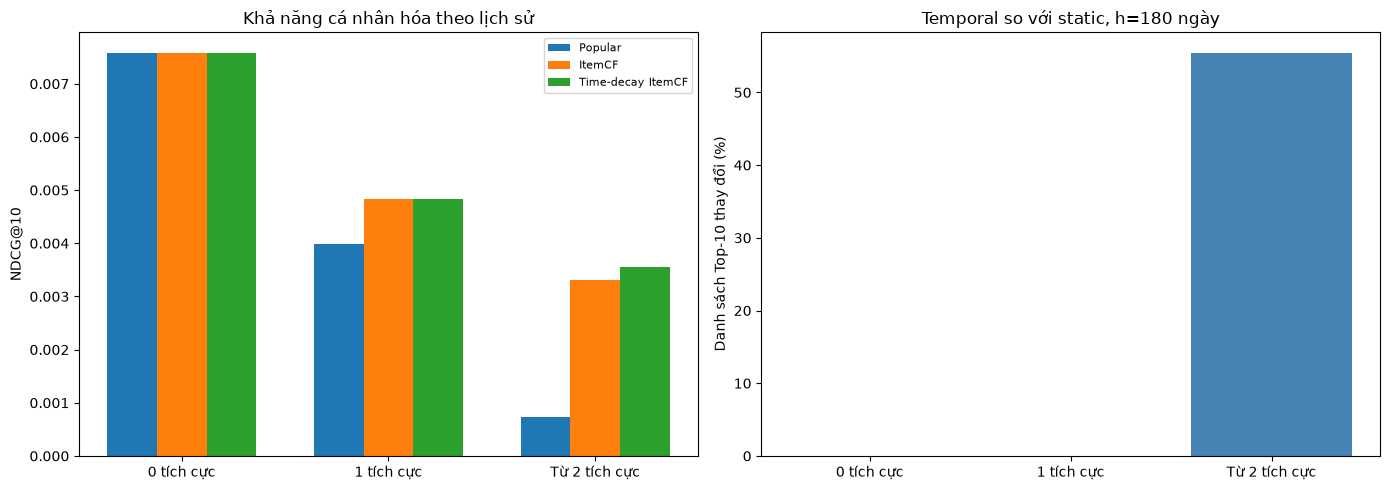

Khoảng tin cậy chứa 0; chưa có bằng chứng rõ temporal cải thiện NDCG@10.
Đã tạo báo cáo temporal: d:\Tài Liệu\RecommenderSystem\reports\temporal_cf\temporal_summary.md


In [18]:
import matplotlib.pyplot as plt

plot_groups = [COHORT_ZERO, COHORT_ONE, COHORT_MULTI]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(plot_groups))
for offset, (label, short) in enumerate([(POPULAR_LABEL, 'Popular'), (CF_LABEL, 'ItemCF'),
                                         (TEMPORAL_LABEL, 'Time-decay ItemCF')]):
    values = personalization_results[
        (personalization_results.k == PRIMARY_K) & (personalization_results.model == label)
    ].set_index('group').reindex(plot_groups)['NDCG@K']
    axes[0].bar(x + (offset - 1) * .24, values, .24, label=short)
axes[0].set_xticks(x, ['0 tích cực', '1 tích cực', 'Từ 2 tích cực'])
axes[0].set_ylabel('NDCG@10')
axes[0].set_title('Khả năng cá nhân hóa theo lịch sử')
axes[0].legend(fontsize=8)
rank_plot = change_summary[change_summary.k == PRIMARY_K].set_index('group').reindex(plot_groups)
axes[1].bar(x, rank_plot.changed_list_fraction * 100, color='steelblue')
axes[1].set_xticks(x, ['0 tích cực', '1 tích cực', 'Từ 2 tích cực'])
axes[1].set_ylabel('Danh sách Top-10 thay đổi (%)')
axes[1].set_title(f'Temporal so với static, h={selected_half_life} ngày')
fig.tight_layout()
fig.savefig(TEMPORAL_REPORT_DIR / 'temporal_comparison.png', dpi=180)
plt.show()
plt.close(fig)

all_temporal_ci = temporal_bootstrap[temporal_bootstrap['group'] == COHORT_ALL].iloc[0]
delta_value = float(all_temporal_ci['mean_NDCG_delta_temporal_minus_static'])
lo, hi = float(all_temporal_ci.CI95_low), float(all_temporal_ci.CI95_high)
if lo > 0:
    temporal_conclusion = 'Temporal có NDCG@10 cao hơn static trong phép đánh giá này.'
elif hi < 0:
    temporal_conclusion = 'Temporal có NDCG@10 thấp hơn static trong phép đánh giá này.'
else:
    temporal_conclusion = 'Khoảng tin cậy chứa 0; chưa có bằng chứng rõ temporal cải thiện NDCG@10.'
metrics_table = personalization_results[personalization_results.k == PRIMARY_K][
    ['model', 'group', 'users', 'NDCG@K', 'Recall@K', 'CF_slot_fraction']].copy()
for column in ['NDCG@K', 'Recall@K', 'CF_slot_fraction']:
    metrics_table[column] = metrics_table[column].map(lambda v: f'{v:.8f}' if pd.notna(v) else 'N/A')
temporal_report = f'''# Temporal Recommendation Baseline — Cường Quốc

## Thiết kế

- Giữ baseline Most Popular và ItemCF; cosine nhị phân, catalog, seen-item filter và fallback không đổi.
- N={final_model.n_neighbors} lấy từ quy tắc validation của baseline. Thử h={list(HALF_LIFE_GRID)} ngày trên validation; chọn h={selected_half_life} ngày bằng NDCG@10 toàn bộ, rồi Recall@10, rồi h nhỏ hơn.
- Mỗi cặp tích cực dùng review tích cực mới nhất trong lịch sử. Trọng số là `2 ** (-age_days / h)` và đi trực tiếp vào tổng điểm ứng viên.
- Validation dùng lịch sử train; test dùng lịch sử train + validation, cố định tại {temporal_model.reference_timestamp_ms} ms. Không cập nhật bằng review test.
- Đối chứng h=∞ tái tạo baseline. Đây là phần mở rộng sau khi baseline đã được báo cáo; không chọn h theo test. Muốn xác nhận độc lập hơn cần một giai đoạn holdout mới.

## Kết quả Top-10 theo số sản phẩm tích cực khác nhau trong lịch sử

{markdown_table(metrics_table)}

## Tác động đến thứ hạng

{markdown_table(change_summary[change_summary.k == PRIMARY_K])}

## Độ bất định và giới hạn

Chênh lệch NDCG@10 temporal trừ static trên toàn bộ: {delta_value:.8f}; CI95% [{lo:.8f}; {hi:.8f}]. {temporal_conclusion}
Bootstrap theo người dùng {BOOTSTRAP_RESAMPLES} lần, seed {SEED}; không bao gồm bất định khi huấn luyện lại hoặc thay đổi giai đoạn.

- Nhóm 0 sản phẩm tích cực dùng Popular. Nhóm 1 sản phẩm tích cực nhận cùng thứ hạng CF vì mọi ứng viên cùng nhân một hệ số dương.
- Với từ 2 sản phẩm tích cực, chênh lệch thời điểm có thể đổi đóng góp tương đối và thứ hạng; cải thiện phải dựa vào số liệu, không được mặc định.
- Nếu không có review mới, dịch chung mốc dự đoán chỉ nhân chung một hệ số; mô hình này chưa mô phỏng cập nhật sở thích trực tuyến.
- Temporal weighting không tạo dữ liệu cho người mới, không đưa sản phẩm ngoài catalog lịch sử vào tập ứng viên và không giải quyết chính thuật toán popularity bias.
- Dữ liệu là review và thời điểm review. Không kết luận hiệu quả doanh thu hay xác suất mua từ điểm CF.
- Handoff Top-100 chỉ bao gồm người dùng test đủ điều kiện đánh giá. Member 2 cần giữ quy tắc đánh giá và ghi rõ thay đổi candidate set nếu mở rộng.

## Tệp kết quả

- `validation_grid.csv`, `selected_config.json`: phép thử và lựa chọn từ validation.
- `test_comparison.csv`, `personalization_groups.csv`, `rank_change_by_group.csv`.
- `test_ndcg10_paired_bootstrap.csv`, `test_per_user.csv.gz`, `test_protocol.json`.
- `temporal_comparison.png`; mô hình temporal ở `models/item_cf_temporal/`.
- Gói dùng cho Member 2 được tạo ở bước bàn giao kế tiếp, trong `models/member2_handoff/` và `models/member2_handoff.zip`.
'''
(TEMPORAL_REPORT_DIR / 'temporal_summary.md').write_text(temporal_report, encoding='utf-8')
print(temporal_conclusion)
print('Đã tạo báo cáo temporal:', TEMPORAL_REPORT_DIR / 'temporal_summary.md')


## 13. Bàn giao mô hình, ứng viên và điểm cho Member 2

Tạo tối đa **100 ứng viên cho mỗi biến thể trên mỗi người dùng test đủ điều kiện đánh giá**. Hai biến thể có Top-100 riêng. Xuất theo luồng vào CSV nén; không xuất nhãn relevance test. Đây là đầu vào cho bước sau, không bao gồm mọi tài khoản hoặc sản phẩm ngoài catalog lịch sử.

`rank` là thứ tự chuẩn. `cf_score` giữ điểm thô; `score` chỉ là phép biến đổi đơn điệu giữ CF ở trước fallback, kèm `score_source` và `ranking_tier`. Module Python được xuất từ hai cell gắn tag, kèm kiểm tra nạp hai mô hình ngoài trạng thái notebook. Giữ tên notebook trên đĩa là `03_tuning_and_test.ipynb` và lưu trước khi chạy ô này.

Gói kết quả nằm dưới `models/` và không cần commit vào GitHub. Với dữ liệu đầy đủ, CSV có thể có hàng triệu dòng; ô này sẽ in tiến độ.


In [19]:
import csv
import gzip
import importlib.util
import shutil
import zipfile

HANDOFF_DIR.mkdir(parents=True, exist_ok=True)
baseline_destination = HANDOFF_DIR / 'baseline_model'
temporal_destination = HANDOFF_DIR / 'temporal_model'
baseline_destination.mkdir(exist_ok=True)
temporal_destination.mkdir(exist_ok=True)
baseline_files = ['user_item_train.npz', 'item_neighbors.npz', 'items.csv',
                  'users.csv.gz', 'popularity.csv', 'seen_history.csv.gz', 'model_config.json']
temporal_files = ['user_item_time_weighted.npz', 'temporal_config.json']
handoff_files = []
for filename in baseline_files:
    shutil.copy2(MODEL_DIR / filename, baseline_destination / filename)
    handoff_files.append(baseline_destination / filename)
for filename in temporal_files:
    shutil.copy2(TEMPORAL_MODEL_DIR / filename, temporal_destination / filename)
    handoff_files.append(temporal_destination / filename)

# Xuất mã nạp/dự đoán từ các cell được gắn tag; Member 2 không cần chạy notebook.
notebook_source_path = PROJECT_DIR / '03_tuning_and_test.ipynb'
if not notebook_source_path.is_file():
    raise FileNotFoundError('Lưu notebook đúng tên 03_tuning_and_test.ipynb tại thư mục gốc dự án.')
notebook_on_disk = json.loads(notebook_source_path.read_text(encoding='utf-8'))
module_parts = []
for tag in ['baseline_model_source', 'temporal_model_source']:
    matching = [c for c in notebook_on_disk['cells'] if tag in c.get('metadata', {}).get('tags', [])]
    if len(matching) != 1:
        raise ValueError(f'Thiếu hoặc trùng cell có tag {tag}; lưu đúng notebook mới rồi Run All.')
    source = matching[0]['source']
    module_parts.append(''.join(source) if isinstance(source, list) else source)
module_path = HANDOFF_DIR / 'baseline_models.py'
module_path.write_text('# Exported from notebook 03; Python + numpy/pandas/scipy/scikit-learn.\n\n'
                       + '\n\n'.join(module_parts) + '\n', encoding='utf-8')
compile(module_path.read_text(encoding='utf-8'), str(module_path), 'exec')
handoff_files.append(module_path)

candidate_path = HANDOFF_DIR / 'candidates_top100.csv.gz'
fieldnames = ['model', 'user_id', 'parent_asin', 'rank', 'score', 'cf_score',
              'positive_user_count', 'ranking_tier', 'score_source',
              'history_positive_count', 'prediction_timestamp_ms']
popularity_counts = dict(zip(final_model.popularity.parent_asin,
                             final_model.popularity.positive_user_count))
candidate_row_count, candidate_preview = 0, []
rows_by_variant = {'itemcf_static': 0, 'itemcf_time_decay': 0}
with gzip.open(candidate_path, 'wt', encoding='utf-8', newline='') as stream:
    writer = csv.DictWriter(stream, fieldnames=fieldnames)
    writer.writeheader()
    for position, user in enumerate(test_truth, start=1):
        for variant, model in [('itemcf_static', final_model), ('itemcf_time_decay', temporal_model)]:
            rows = scored_recommendations(model, user, CANDIDATE_K, popularity_counts)
            assert len(rows) == len({row['parent_asin'] for row in rows})
            assert all(row['parent_asin'] not in model.seen.get(user, set()) for row in rows)
            if position <= 5:
                assert [row['parent_asin'] for row in rows] == model.recommend(user, CANDIDATE_K)
                assert all(rows[i]['score'] >= rows[i + 1]['score'] for i in range(len(rows) - 1))
            for row in rows:
                row['model'] = variant
                writer.writerow(row)
                if position <= 2 and row['rank'] <= 20:
                    candidate_preview.append(row.copy())
            candidate_row_count += len(rows)
            rows_by_variant[variant] += len(rows)
        if position % 5000 == 0:
            print(f'Handoff: {position:,}/{len(test_truth):,} người dùng; {candidate_row_count:,} dòng', flush=True)
handoff_files.append(candidate_path)
preview_path = TEMPORAL_REPORT_DIR / 'candidate_preview.csv'
pd.DataFrame(candidate_preview).to_csv(preview_path, index=False, encoding='utf-8-sig')

copy_reports = [
    (SELECTION_PATH, 'static_selected_config.json'),
    (TEMPORAL_SELECTION_PATH, 'temporal_selected_config.json'),
    (TEMPORAL_REPORT_DIR / 'test_comparison.csv', 'test_comparison.csv'),
    (TEMPORAL_REPORT_DIR / 'personalization_groups.csv', 'personalization_groups.csv'),
    (TEMPORAL_REPORT_DIR / 'rank_change_by_group.csv', 'rank_change_by_group.csv'),
    (TEMPORAL_REPORT_DIR / 'test_ndcg10_paired_bootstrap.csv', 'test_ndcg10_paired_bootstrap.csv')
]
for source, name in copy_reports:
    destination = HANDOFF_DIR / name
    shutil.copy2(source, destination)
    handoff_files.append(destination)
handoff_readme = f'''# Bàn giao Member 2 — Temporal Recommendation Baseline

Người thực hiện: Cường Quốc. N={final_model.n_neighbors}; h={selected_half_life} ngày.

## Phạm vi

`candidates_top100.csv.gz` có {candidate_row_count:,} dòng của hai biến thể `itemcf_static` và `itemcf_time_decay`, tối đa {CANDIDATE_K} ứng viên cho mỗi biến thể/người dùng.
Phạm vi là {len(test_truth):,} người dùng test có ít nhất một sản phẩm tích cực mới đủ điều kiện đánh giá. Đây không phải toàn bộ tài khoản hay toàn bộ người viết review trong test.
Lịch sử cố định ở cuối train + validation ({temporal_model.reference_timestamp_ms} ms); dữ liệu test không dùng để học, tính trọng số hay chọn tham số. Danh sách ứng viên không chứa nhãn relevance từ test.
Sản phẩm nằm ngoài catalog lịch sử không có trong candidate set. Rerank chỉ có thể sắp xếp lại các ứng viên đã xuất; muốn mở rộng phải chạy mô hình hoặc bổ sung nguồn ứng viên và báo cáo rõ thay đổi.

## Cách nạp

Cài `numpy pandas scipy scikit-learn`; thêm `pyarrow` nếu đọc các split Parquet riêng. Đứng tại thư mục vừa giải nén:

```python
from pathlib import Path
import pandas as pd
from baseline_models import ItemCFModel, TimeDecayItemCF, scored_recommendations

root = Path('.')
baseline = ItemCFModel.load(root / 'baseline_model')
temporal = TimeDecayItemCF.load(root / 'temporal_model', baseline)
user_id = 'THAY_BANG_USER_ID_CAN_GOI_Y'
recommendations = pd.DataFrame(scored_recommendations(temporal, user_id, k=100))
# Đọc theo chunk để không đưa toàn bộ CSV lớn vào RAM:
for chunk in pd.read_csv(root / 'candidates_top100.csv.gz', chunksize=100_000,
                         dtype={{'user_id': 'string', 'parent_asin': 'string'}}):
    pass  # xử lý/lưu từng chunk theo nhu cầu
```

## Hợp đồng dữ liệu và điểm số

- Khóa duy nhất: (`model`, `user_id`, `rank`); mã sản phẩm trong từng danh sách không lặp. Giữ ID dạng chuỗi.
- `rank`: thứ hạng cuối bắt đầu từ 1, là thứ tự chuẩn để khôi phục danh sách.
- `cf_score`: tổng cosine (baseline) hoặc tổng cosine nhân trọng số thời gian (temporal); fallback có giá trị 0.
- `positive_user_count`: độ phổ biến theo số người dùng tích cực khác nhau trong lịch sử.
- `score_source`: `CF` hoặc `Most Popular fallback`; `ranking_tier`: 1 hoặc 0 tương ứng.
- `score`: điểm vô hướng giữ nguyên chính sách CF trước, fallback sau. CF dùng `1 + cf_score/(1+cf_score)`; fallback dùng `positive_user_count/(1+max_positive_user_count)`. Nếu bằng điểm, theo `parent_asin` tăng dần. Không so sánh điểm giữa các người dùng như xác suất hay độ tin cậy đã hiệu chỉnh.
- `history_positive_count`: số sản phẩm tích cực khác nhau trong lịch sử; `prediction_timestamp_ms`: mốc dự đoán, đơn vị mili giây.
- `model`, `user_id`, `parent_asin` và các trường trên dùng chung schema cho hai biến thể; mỗi biến thể có danh sách Top-100 riêng. Không ghép hai danh sách như thể cùng candidate set.

## Tái lập và giới hạn

`manifest.json` lưu cấu hình, phiên bản thư viện, số dòng và SHA256 các tệp. Hai thư mục mô hình phải được giữ cùng nhau; temporal sử dụng cosine của baseline kèm ma trận trọng số riêng.
Giữ mốc chia thời gian, định nghĩa rating >= 4, nhóm đánh giá, chính sách loại sản phẩm đã đánh giá và cách tính chỉ số khi so sánh. Timestamp là thời điểm review.
Cường Quốc bàn giao baseline và thí nghiệm thời gian; không chịu trách nhiệm chính về thuật toán giảm popularity bias, TKG hoặc LLM.
'''
handoff_readme_path = HANDOFF_DIR / 'README_MEMBER2.md'
handoff_readme_path.write_text(handoff_readme, encoding='utf-8')
handoff_files.append(handoff_readme_path)

# Kiểm tra mã xuất có thể nạp đủ hai mô hình mà không dựa vào biến notebook.
spec = importlib.util.spec_from_file_location('member2_baseline_models', module_path)
member2_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(member2_module)
handoff_baseline = member2_module.ItemCFModel.load(baseline_destination)
handoff_temporal = member2_module.TimeDecayItemCF.load(temporal_destination, handoff_baseline)
for user in list(test_truth)[:5] + ['__new_user__']:
    assert handoff_baseline.recommend(user, 20) == final_model.recommend(user, 20)
    assert handoff_temporal.recommend(user, 20) == temporal_model.recommend(user, 20)
    original = scored_recommendations(temporal_model, user, 20, popularity_counts)
    restored = member2_module.scored_recommendations(handoff_temporal, user, 20, popularity_counts)
    assert original == restored
del handoff_baseline, handoff_temporal
gc.collect()


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


manifest = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(), 'author': 'Cường Quốc',
    'models': list(rows_by_variant), 'candidate_k': CANDIDATE_K,
    'eligible_test_users': len(test_truth), 'candidate_rows': candidate_row_count,
    'rows_by_variant': rows_by_variant,
    'scope': 'test users with at least one novel positive review; fixed train+validation history',
    'contains_test_relevance_labels': False,
    'prediction_timestamp_ms': temporal_model.reference_timestamp_ms,
    'selected_n_neighbors': final_model.n_neighbors, 'selected_half_life_days': selected_half_life,
    'static_training_fingerprint': final_model.training_fingerprint,
    'static_selection_sha256': selection_sha256, 'temporal_selection_sha256': temporal_selection_sha256,
    'versions': selection['versions'], 'score_policy': 'cf_first_monotone_v1',
    'files': [{'path': str(path.relative_to(HANDOFF_DIR)).replace('\\', '/'),
               'bytes': path.stat().st_size, 'sha256': sha256_file(path)} for path in handoff_files]
}
write_json(HANDOFF_DIR / 'manifest.json', manifest)
handoff_files.append(HANDOFF_DIR / 'manifest.json')
if MAKE_HANDOFF_ZIP:
    zip_path = HANDOFF_DIR.with_suffix('.zip')
    with zipfile.ZipFile(zip_path, 'w') as archive:
        for path in handoff_files:
            compression = zipfile.ZIP_STORED if path.suffix in {'.gz', '.npz'} else zipfile.ZIP_DEFLATED
            archive.write(path, str(path.relative_to(HANDOFF_DIR)), compress_type=compression)
    print('Gói bàn giao:', zip_path)
write_json(TEMPORAL_REPORT_DIR / 'handoff_summary.json', {
    'eligible_test_users': len(test_truth), 'candidate_k': CANDIDATE_K,
    'candidate_rows': candidate_row_count, 'rows_by_variant': rows_by_variant,
    'handoff_directory': str(HANDOFF_DIR.relative_to(PROJECT_DIR)),
    'zip_created': MAKE_HANDOFF_ZIP, 'standalone_load_check': 'passed'
})
print('Đã bàn giao mã nạp mô hình, hai mô hình, candidate/score/rank và cấu hình.')
print('Thư mục:', HANDOFF_DIR)
print('Bản xem nhanh:', preview_path)


Handoff: 5,000/43,656 người dùng; 1,000,000 dòng
Handoff: 10,000/43,656 người dùng; 2,000,000 dòng
Handoff: 15,000/43,656 người dùng; 3,000,000 dòng
Handoff: 20,000/43,656 người dùng; 4,000,000 dòng
Handoff: 25,000/43,656 người dùng; 5,000,000 dòng
Handoff: 30,000/43,656 người dùng; 6,000,000 dòng
Handoff: 35,000/43,656 người dùng; 7,000,000 dòng
Handoff: 40,000/43,656 người dùng; 8,000,000 dòng
Gói bàn giao: d:\Tài Liệu\RecommenderSystem\models\member2_handoff.zip
Đã bàn giao mã nạp mô hình, hai mô hình, candidate/score/rank và cấu hình.
Thư mục: d:\Tài Liệu\RecommenderSystem\models\member2_handoff
Bản xem nhanh: d:\Tài Liệu\RecommenderSystem\reports\temporal_cf\candidate_preview.csv
